In [ ]:
#copied "EDITED"

Data Clean Up document from 2022:

https://drive.google.com/drive/folders/1-m-4NOTqvHZlHqPQW37XGDqIVfp1zfRG?usp=sharing

# Comprehensive:

### TO DO:

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
import json
#1
# Make sure you copy the folder to your personal drive (or create a shortcut <- easier)

#TO DO - everything needed modifying is done here
# update to the semester if needed (check where the data is ON YOUR drive)

folder = "2024 Fall - Data/"
data_folder = "2019-2023 cleaned"

# Edit path based on where your data folder is
#for data read in
root_path = "/My Drive/ECI Research/5. Datasets/"
path_to_data =  root_path+folder
GDP4_path = root_path+"2024 Fall - Data"

#TO DO: MODIFY T0 YOUR COUNTRY below
  # No need change elsewhere, unless stated otherwise
main_country = "Thailand"

#TO DO: MODIFY YOUR COMPARABLE COUNTRIES HERE
  # make sure to include your main country (you modified already above)
comparable_countries = [main_country, 'Chile', 'Malaysia']

#emerging economies for SDV:
sdv_emerging_countries = ["China", "Singapore"]

#leading economies for SDV:
sdv_leading_countries = ['France, Monaco', 'Greece', 'Portugal']

#SDV's list - any possible note name changes
sdv_comparable_countries = [main_country, 'Greece', 'Poland', 'Portugal', 'France, Monaco']

#path for sdv_and_sids folder:
#sdv_path = root_path + "/New_result_update/sdv_and_sids/"
sdv_path = root_path + "2019-2023 cleaned/2023clean.csv"

# Change to relevant years
begin_year = 2019
end_year = 2023



os.makedirs("/content/drive/My Drive/ECI Auto Report Test/img", exist_ok=True)

category = "emerging" #developed or emerging

jsonpath = f'/content/drive/My Drive/ECI Auto Report Test/{main_country}.json'

jsonout = {}

if os.path.exists(jsonpath):
      with open(jsonpath, 'r') as f:
        jsonout = json.load(f)

jsonout["[Country]"] = main_country
jsonout["[Category]"] = category


In [ ]:
#!rm -rf /content/drive

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
import os

base_path = '/content/drive/My Drive'

print(f"\nFolders in: {base_path}")
for f in os.listdir(base_path):
    full_path = os.path.join(base_path, f)
    if os.path.isdir(full_path):
        print("📁", f)
    else:
        print("📄", f)


Folders in: /content/drive/My Drive
📁 Clubs
📁 Textbooks
📁 Miscellaneous
📁 University Writing
📄 New Logo and Brand Materials
📄 hw2 (2).pdf
📄 Sep 22 recitation notes.pdf
📄 Econ quiz 1 practice.pdf
📄 Sin tax externality graph.pdf
📄 UN1105_2023 Fall_Noor_PS #1.pdf
📄 Oct 13 recitation .pdf
📄 2023-09-28 17-17.pdf
📄 UN1105_2023 Fall_Noor_PS #2_05.pdf
📄 Will Li General Cover Letter.gdoc
📄 Copy of Trackr: Summer Internships 2024 25 - North America.gsheet
📄 Amand Ventures March 2024 Study Guide.gdoc
📁 Recruiting
📄 text_0.txt
📄 Lithum Discussion 3 21.gdoc
📄 Experience.gdoc
📄 Will Li Review of ECON questions.gdoc
📄 Morgan Stanley Sophomore Summer Analyst Hirevues.gdoc
📄 DSC07956.ARW
📄 Amand Call 4 4.gdoc
📄 CREG Spring 2024 Interest Rates Presentation.gslides
📄 Cc Professor rankings.gdoc
📄 TASA Eboard 2024-25 election.gslides
📄 CapM Interview Notes 2025.gdoc
📄 Will Li CAP IG Posters (1).zip
📄 Will Li Literature Humanities Final Written Assignment - Culmination.gdoc
📄 lecture2.pdf
📄 Untitled docume

#### Import Packages

In [5]:
#3
# only run once - uncomment if needed

!pip install xlwt
!pip install -U kaleido #Install the kaleido package for exporting images

#needed to downgrade plotly for kaleido to work; the code seems to run fine with the lower version,
#but let me know if we run into issues
!pip install --upgrade plotly
!pip install dataframe_image[all]


  Using cached plotly-6.1.1-py3-none-any.whl.metadata (6.9 kB)
Using cached plotly-6.1.1-py3-none-any.whl (16.1 MB)
  Attempting uninstall: plotly
    Found existing installation: plotly 5.3.1
    Uninstalling plotly-5.3.1:
      Successfully uninstalled plotly-5.3.1


In [6]:

from google.colab import files # not needed for personal
import io
import os
from tqdm import tqdm
import csv
import dataframe_image as dfi

import statsmodels.api as sm
import statsmodels.formula.api as smf
import math
from sklearn.linear_model import LinearRegression

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
from scipy import linalg as LA
import operator
from xlwt import Workbook
import xlwt
if not hasattr(np, 'bool8'): #
    np.bool8 = np.bool_
import plotly.express as px

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pickle

zzz=np.random.randint(1,100)

#### Import Data

In [7]:
#5
# Base path for the data - path_to_data = "drive/My Drive/ECI Research/5. Datasets/2023 Fall - Data/"

# Read input - CHECK DATA FOR RELEVANCE
#uploaded = files.upload()
#NZ created 2019-2022 cleaned folder
df1 = pd.read_csv('/content/drive/My Drive/Copyof2019clean.csv') #index_col=0)
df2 = pd.read_csv('/content/drive/My Drive/Copyof2020clean.csv')
df3 = pd.read_csv('/content/drive/My Drive/Copyof2021clean.csv')
df4 = pd.read_csv('/content/drive/My Drive/Copyof2022clean.csv') #!!! added for new year - JZ
df5 = pd.read_csv('/content/drive/My Drive/Copyof2023clean.csv') # added for 2023 - JZ

gdp_df = pd.read_csv('/content/drive/My Drive/Copy of GDP_2023.csv')
gdp_df = gdp_df.drop(columns=['Country Code', 'Series Name']).rename(columns={'Country Name': 'Country'})

In [8]:
# turns dataframe into matrix, cleans and checks data as well (nonzero values)
def df_to_matrix(dfa):
  raw_matrixa = dfa.to_numpy()
  matrixa = [list(dfa.columns)]

  for row in raw_matrixa:
    stripped=np.char.strip(np.array(row[1::]).astype(str),chars='_')

    if np.count_nonzero(stripped.astype(float))>=16:
      matrixa.append(list(row))

  return matrixa

dataframes = [df1, df2, df3, df4, df5] #!!! edited to add 2022 - JZ *Data Updte
mxlist = []
for data in dataframes:
    mxlist.append(df_to_matrix(data))

# to be consistent with naming -> used in ECI
matrix = mxlist[0]
matrix2 = mxlist[1]
matrix3 = mxlist[2]
matrix4 = mxlist[3] #!!! same here - JZ *Data Updte
matrix5 = mxlist[4]

#matrix = df_to_matrix(df_2019) #for 2019
#matrix2 = df_to_matrix(df_middle) #for 2020
#matrix3 = df_to_matrix(df_end) #for 2021

In [9]:
# Find values that do not match
#mismatch_values = gdp_df[~gdp_df['Country'].isin(df1['Country'])]['Country']

# Display or use mismatch values as needed
#print("Mismatch values:", mismatch_values.tolist())

mismatch_values = np.array(gdp_df[~gdp_df['Country'].isin(df1['Country'])]['Country'])
#print("Mismatch values:", mismatch_values)

all_countries_used = (
    comparable_countries +
    sdv_emerging_countries +
    sdv_leading_countries +
    sdv_comparable_countries
)

all_countries_used = list(set(all_countries_used))

# Print the resulting array
print("All country names used:")
print(all_countries_used)

bad_countries_used = [country for country in all_countries_used if country in mismatch_values]
print("Bad names in GDP file - pls fix if needed:")
print(bad_countries_used)


All country names used:
['Singapore', 'Chile', 'Malaysia', 'Portugal', 'Greece', 'France, Monaco', 'Thailand', 'Poland', 'China']
Bad names in GDP file - pls fix if needed:
[]


In [10]:
# this block is to fix mismatching names
for country_name in all_countries_used:
        if country_name == 'Plurinational State of Bolivia':
            gdp_df[country_name] = 'Bolivia'
        elif country_name == 'Norway, Svalbard and Jan Mayen':
            gdp_df[country_name] = 'Norway'
        elif country_name == 'Russian Federation':
            gdp_df[country_name] = 'Russia'
        elif country_name == 'Korea, Rep.':
            gdp_df[country_name] = 'South Korea'
        elif country_name == 'France, Monaco':
            gdp_df[country_name] = 'France'


In [11]:
# this is both fidning missing data and making a dict for GDP
def find_missing_data(df):
    missing_data = []
    gdp_dict = {}

    for index, row in df.iterrows():
        country = row['Country']
        year_value_list =[]

         # Get last 4 years to analyze NA's
        for col in df.iloc[:, (begin_year - end_year - 2):]:

            if pd.isna(row[col]) or not pd.notna(pd.to_numeric(row[col], errors='coerce')):
                    missing_data.append((country, col))
            else:
                   year_value_list.append((col, row[col]))
        gdp_dict[country] = year_value_list

    missing_data_df = pd.DataFrame(missing_data, columns=['Country', 'Year'])
    return missing_data_df, gdp_dict

missing_data_df, gdp_range_dict = find_missing_data(gdp_df)
#print(missing_data_df)
#gdp_range_dict

In [12]:
gdp_df_filtered = gdp_df[['Country', '2019', '2020', '2021', '2022', '2023']] #*Data Updte

'''
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

print(gdp_df_filtered)

pd.reset_option('display.max_rows')
pd.reset_option('display.max_columns')
'''
#Use this block to update values if they are missing:
print(main_country, gdp_df_filtered.loc[gdp_df_filtered['Country'] == main_country, ['2019', '2020', '2021', '2022', '2023']].values[0]) #*Data Updte

# To change the value in OG dataframe:
# gdp_df.loc[gdp_df['Country Name'] == main_country, '2019'] = -100
# gdp_df.head()

Thailand [5.44e+11 5.00e+11 5.06e+11 4.95e+11 5.15e+11]


In [13]:
matrix5

[['Country',
  'Animals and By-products',
  'Vegetables, Fruits and Plants',
  'Food and Preparations',
  'Energy Drilling and Mining',
  'Chemicals',
  'Chemical Manufacturing',
  'Raw Manufacturing',
  'Wood Products',
  'Clothing and Accessories',
  'Textile',
  'Metals',
  'Machinery and Construction',
  'Transportation',
  'Weapons',
  'Daily Instruments',
  'Precious Stones\t',
  'High-complexity Products',
  'Services and Utilities'],
 ['Albania',
  840841652.8510001,
  1312255979.184,
  1168879257.762,
  3832449006.803,
  57199331.98,
  410605940.25,
  650648188.707,
  678652939.501,
  8814764378.92,
  25848087.006,
  4570214206.937,
  109773677.198,
  1458595475.296,
  12369753.616,
  407065361.288,
  129640957.386,
  10820840586.842,
  10282743462.214],
 ['Andorra',
  760403.193,
  2007.56,
  2172680.174,
  300989.011,
  36547.06,
  3881437.876,
  3618370.553,
  14088608.69,
  15948288.997,
  418620.871,
  5271191.903999999,
  44310.812,
  104813760.965,
  284103.141,
  33174

## ECI & PCI

MCP

In [14]:
#compute mcp
#input is matrix, output is the original product and country lists, the MCP values, the product sums, and the country sums

def compute_mcp(matrix):
  product_list = matrix[0][1::]

  country_list = []
  for i in range(1,len(matrix)):
    country_list.append(matrix[i][0])

  country_sum = []
  for i in range(1,len(matrix)):
    stripped=np.char.strip(np.array(matrix[i][1::]).astype(str),chars='_')
    country_sum.append(np.sum(stripped.astype(float)))

  product_sum = []
  for i in range(1,len(matrix[0])):
    product = 0
    for j in range(1,len(matrix)):
        product += matrix[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcp = []

  for i in range (1,len(matrix)):
    country_row = []
    for j in range(1,len(matrix[i])):
      try:
        percentage = matrix[i][j]/country_sum[i-1]
      except:
        print(country_list[i-1])
      total_percentage = product_sum[j-1]/total_sum
      if percentage > total_percentage:
        country_row.append(1)
      else:
        country_row.append(0)
    mcp.append(country_row)

  return country_list,product_list,mcp,product_sum,country_sum

MCC

In [15]:
#computes mcc from mcp
def compute_mcc(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcc = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp)):
      temp_sum = 0
      for k in range(0,len(mcp[0])):
        try:
          value = (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
          if np.isinf(value) or np.isnan(value):
            temp_sum += 0
          else:
            temp_sum += value
        except:
          pass
      country_row.append(temp_sum)
    mcc.append(country_row)
  return mcc

MPP

In [16]:
# compute mpp from mcp
def compute_mpp(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)
  print(country_sum)
  print(product_sum)
  mpp = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += (mcp[k][i] * mcp2[k][j]/(country_sum[k]*product_sum[i]))
        except:
          pass
      product_row.append(temp_sum)
    mpp.append(product_row)
  return mpp

ECI

In [17]:
#compute ECI from mcc
def compute_eci(mcc):
  mcc = np.array(mcc)

  e_vals, e_vecs = LA.eig(mcc)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  eci = []
  if vector[0] < 0:
    for item in vector:
      eci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      eci.append((-item+np.mean(vector))/np.std(vector))
  return eci

PCI

In [18]:
#compute PCI from mpp
def compute_pci(mpp):
  mpp = np.array(mpp)
  e_vals, e_vecs = LA.eig(mpp)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  pci = []
  if vector[len(vector)-2] > 0:
    for item in vector:
      pci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      pci.append((-item+np.mean(vector))/np.std(vector))
  return pci


In [19]:
#matrix is for year 2019
#matrix2 is for year 2020
#FOR THIS UPDATE ONLY USE YEAR 2021 (matrix3)

country_list,product_list,mcp,product_sum,country_sum = compute_mcp(matrix5)#*Data Updte
country_list_last_year,product_list_last_year,mcp_last_year,product_sum_last_year,country_sum_last_year = compute_mcp(matrix4) #*Data Updte

mcc = compute_mcc(mcp)
mpp = compute_mpp(mcp)
display(mpp)
mcc_last_year = compute_mcc(mcp_last_year)
mpp_last_year = compute_mpp(mcp_last_year)

eci = compute_eci(mcc)
pci = compute_pci(mpp)

eci_last_year = compute_eci(mcc_last_year)
pci_last_year = compute_pci(mpp_last_year)

#check ECI
eci_dict = {}
for i in range(len(country_list)):
  eci_dict[country_list[i]]=eci[i]
sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))

#check PCI
pci_dict = {}
for i in range(len(product_list)):
  pci_dict[product_list[i]]=pci[i]
sorted_pci_dict = sorted(pci_dict.items(), key=operator.itemgetter(1))

#check ECI
eci_dict_last_year = {}
for i in range(len(country_list_last_year)):
  eci_dict_last_year[country_list_last_year[i]]=eci_last_year[i]
sorted_eci_dict_last_year = sorted(eci_dict_last_year.items(), key=operator.itemgetter(1))

# Tester if needed:
# print(sorted_eci_dict)
# for item in sorted_pci_dict:
 # print(item)

[np.int64(5), np.int64(5), np.int64(3), np.int64(6), np.int64(4), np.int64(5), np.int64(4), np.int64(5), np.int64(8), np.int64(2), np.int64(6), np.int64(4), np.int64(4), np.int64(8), np.int64(4), np.int64(4), np.int64(6), np.int64(6), np.int64(10), np.int64(2), np.int64(7), np.int64(2), np.int64(9), np.int64(5), np.int64(2), np.int64(5), np.int64(9), np.int64(4), np.int64(2), np.int64(7), np.int64(9), np.int64(2), np.int64(8), np.int64(4), np.int64(6), np.int64(7), np.int64(11), np.int64(4), np.int64(8), np.int64(3), np.int64(7), np.int64(6), np.int64(2), np.int64(9), np.int64(6), np.int64(10), np.int64(8), np.int64(8), np.int64(5), np.int64(9), np.int64(7), np.int64(6), np.int64(10), np.int64(3), np.int64(5), np.int64(9), np.int64(4), np.int64(9), np.int64(8), np.int64(8), np.int64(3), np.int64(4), np.int64(4), np.int64(4), np.int64(10), np.int64(8), np.int64(5), np.int64(8), np.int64(9), np.int64(5), np.int64(8), np.int64(7), np.int64(4), np.int64(8), np.int64(1), np.int64(8), np.int

[[np.float64(0.1720676845676845),
  np.float64(0.10665048165048162),
  np.float64(0.10951942201942202),
  np.float64(0.08821418821418818),
  np.float64(0.02042090792090792),
  np.float64(0.03063696813696814),
  np.float64(0.043437268437268445),
  np.float64(0.06755196755196757),
  np.float64(0.05563160563160563),
  np.float64(0.04767803517803519),
  np.float64(0.0701098826098826),
  np.float64(0.016548691548691548),
  np.float64(0.016248391248391246),
  np.float64(0.031178581178581178),
  np.float64(0.033720408720408726),
  np.float64(0.04701844701844702),
  np.float64(0.018441655941655942),
  np.float64(0.024925412425412425)],
 [np.float64(0.09508597159199572),
  np.float64(0.18500756271840604),
  np.float64(0.12786470557554896),
  np.float64(0.0883160347015769),
  np.float64(0.022323058467636783),
  np.float64(0.026970653175472457),
  np.float64(0.0437329404196874),
  np.float64(0.05745405865887795),
  np.float64(0.05850631965089797),
  np.float64(0.05545993497800726),
  np.float64(0

[np.int64(6), np.int64(2), np.int64(6), np.int64(4), np.int64(7), np.int64(5), np.int64(5), np.int64(7), np.int64(2), np.int64(5), np.int64(4), np.int64(4), np.int64(9), np.int64(4), np.int64(4), np.int64(3), np.int64(5), np.int64(8), np.int64(1), np.int64(7), np.int64(2), np.int64(10), np.int64(5), np.int64(3), np.int64(8), np.int64(7), np.int64(9), np.int64(2), np.int64(7), np.int64(4), np.int64(6), np.int64(6), np.int64(11), np.int64(5), np.int64(8), np.int64(2), np.int64(8), np.int64(10), np.int64(5), np.int64(10), np.int64(7), np.int64(7), np.int64(4), np.int64(7), np.int64(7), np.int64(5), np.int64(11), np.int64(5), np.int64(8), np.int64(9), np.int64(8), np.int64(4), np.int64(9), np.int64(3), np.int64(5), np.int64(3), np.int64(9), np.int64(8), np.int64(5), np.int64(5), np.int64(10), np.int64(5), np.int64(8), np.int64(7), np.int64(4), np.int64(8), np.int64(1), np.int64(9), np.int64(6), np.int64(7), np.int64(5), np.int64(10), np.int64(5), np.int64(4), np.int64(3), np.int64(7), np.i

## Section 2: Graphs (ECI and GDP)

In [20]:
##Changing matrices into dictionary format
def get_eci_dict(mat):
  country_list,product_list,mcp,product_sum,country_sum = compute_mcp(mat)
  mcc = compute_mcc(mcp)
  eci = compute_eci(mcc)
  eci_dict = {}
  for i in range(len(country_list)):
    eci_dict[country_list[i]]=eci[i]
  sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))
  return sorted_eci_dict

In [21]:
## Changing matrices into dictionary format
# matrix3 is for 2021
matrix3 = df_to_matrix(df3)
#print(matrix3[3])
matrix3[18][3] = matrix3[18][3] *1

eci_2019 = get_eci_dict(matrix)
eci_2020 = get_eci_dict(matrix2)
eci_2021 = get_eci_dict(matrix3)
eci_2022 = get_eci_dict(matrix4) #!!! 2022 addition - JZ
eci_2023 = get_eci_dict(matrix5) #*Data Update

In [22]:
from collections import defaultdict
eci_list = [eci_2019, eci_2020, eci_2021, eci_2022, eci_2023] #*Data Update
eci_19to21_dict = defaultdict(list)
i = 0
for li in eci_list:
  for entry in li:
    eci_19to21_dict[entry[0]].append((2019+i, entry[1]))
  i += 1

#this is a test for your country (you modified above)
# eci_19to21_dict[main_country]

#create a dataframe to export the data into a document
df = pd.DataFrame(eci_19to21_dict[main_country], columns=['Year', 'ECI'])

#make file name easily changeable
year_name = '_eci_'+ str(begin_year)[2:] + 'to' + str(end_year)[2:] + '_dict'

#export to text document
filename = main_country + year_name + '.txt'
with open(filename, 'w') as f:
  f.write(df.to_string())

#export to excel
filename = main_country + year_name + '.xlsx'
df.to_excel(filename, index=False)

In [23]:
eci_19to21_dict['Togo']

[(2019, np.float64(-0.2877841796628254)),
 (2020, np.float64(0.38044591378968484)),
 (2021, np.float64(0.7472235054329438)),
 (2022, np.float64(0.2554718536861984)),
 (2023, np.float64(0.3850100778797647))]

Average Annual Growth Rate

In [24]:
#calculates average annual growth rate
def aagrate(nums):
  tot = 0
  i = 0
  while i < len(nums) - 1:
    tot += (((nums[i+1]-nums[i])/nums[i]) * 100)
    i += 1
  return tot/len(nums)

GDP Peer Comparison Graph

In [25]:
# 1. See all your keys (or filter them)
all_keys = list(gdp_range_dict.keys())
print("All country keys:", all_keys)

# Or just look for anything containing “France”:
print([k for k in all_keys if "France" in k])

# 2. If you want to treat "France, Monaco" as a single key,
#    merge their data lists and assign it yourself:
fr_data = gdp_range_dict.get("France", [])
mc_data = gdp_range_dict.get("Monaco", [])

if not fr_data:
    print("Warning: no data for 'France'")
if not mc_data:
    print("Warning: no data for 'Monaco'")

# Combine them into one list and assign back into the dict:
gdp_range_dict["France, Monaco"] = fr_data + mc_data

y_values = [float(x[1]) / (10 ** 9) for x in gdp_range_dict[country_name]]

#x = int(x_values)
y_values
gdp_range_dict['Togo']


All country keys: ['Aruba', 'Africa Eastern and Southern', 'Afghanistan', 'Africa Western and Central', 'Angola', 'Albania', 'Andorra', 'Arab World', 'United Arab Emirates', 'Argentina', 'Armenia', 'American Samoa', 'Antigua and Barbuda', 'Australia', 'Austria', 'Azerbaijan', 'Burundi', 'Belgium', 'Benin', 'Burkina Faso', 'Bangladesh', 'Bulgaria', 'Bahrain', 'Bahamas, The', 'Bosnia and Herzegovina', 'Belarus', 'Belize', 'Bermuda', 'Bolivia', 'Brazil', 'Barbados', 'Brunei Darussalam', 'Bhutan', 'Botswana', 'Central African Republic', 'Canada', 'Central Europe and the Baltics', 'Switzerland', 'Channel Islands', 'Chile', 'China', "Cote d'Ivoire", 'Cameroon', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Colombia', 'Comoros', 'Cabo Verde', 'Costa Rica', 'Caribbean small states', 'Cuba', 'Curacao', 'Cayman Islands', 'Cyprus', 'Czechia', 'Germany', 'Djibouti', 'Dominica', 'Denmark', 'Dominican Republic', 'Algeria', 'East Asia & Pacific (excluding high income)', 'Early-demographic dividend', 'East Asia

[('2019', 6992656429.0),
 ('2020', 7389329393.0),
 ('2021', 8334047486.0),
 ('2022', 8126439481.0),
 ('2023', 9171261838.0)]

[2019, 2020, 2021, 2022, 2023]
[2019, 2020, 2021, 2022, 2023]
[2019, 2020, 2021, 2022, 2023]


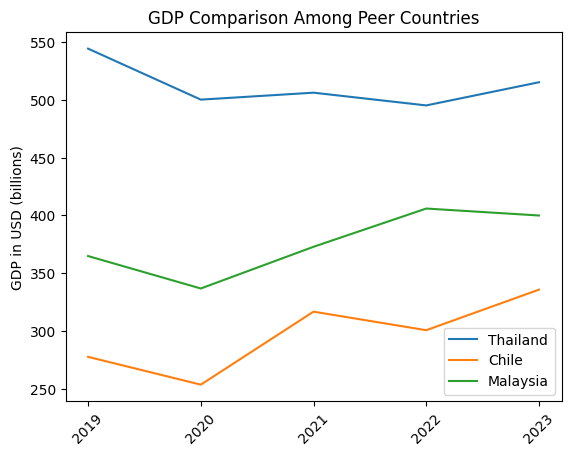

In [26]:
# MD FIXed
# to fix - names:
def gdp_comparison_graph(cnames):
    from matplotlib.ticker import MultipleLocator
    fig, ax = plt.subplots()

    #FIX - naming fixes
    for country_name in cnames:

        label = country_name

        x_values = [int(x[0]) for x in gdp_range_dict[country_name]]
        y_values = [float(x[1]) / (10 ** 9) for x in gdp_range_dict[country_name]]
        print(x_values)

        # Create the plot
        max_ticks = 4  # You can adjust this number as needed
        #ax.xaxis.set_major_locator(plt.MaxNLocator(max_ticks))
        ax.xaxis.set_major_locator(MultipleLocator(1))
        # Ensure that tick marks on the x-axis are integers
        #ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x_values, _: int(x_values)))
        ax.tick_params(axis='x', rotation=45)
        ax.plot(x_values, y_values, label=label)

    plt.ylabel('GDP in USD (billions)')
    plt.legend()
    plt.title('GDP Comparison Among Peer Countries')

    # Export the file as a downloadable png
    plt.savefig(f'/content/drive/My Drive/ECI Auto Report Test/img/kix.2h1zoxev3wer.png')

    # Show the plot
    plt.show()

    return plt

plt = gdp_comparison_graph(comparable_countries)

# Show the plot
plt.show()

In [27]:
# TO FIX - merge with above fixing_missing_values
#to deal with NA values
gdp_range_dict['United Arab Emirates'][2] = (2021, 415000000000)

In [28]:
# TO FIX - not CAGR in the file

def printgdps(cns):
   for cn in cns:
     print(cn)
     if cn == main_country:
      grwth = round(aagrate([x[1] for x in gdp_range_dict[cn]]),2)
      jsonout["[GDP growth rate]"] = str(grwth)
      if grwth > 3:
        jsonout["[GDP growth quality]"] = "high"
      elif grwth > 1:
        jsonout["[GDP growth quality]"] = "moderate"
      else:
        jsonout["[GDP growth quality]"] = "low"
      print(grwth)
     else:
      print(round(aagrate([x[1] for x in gdp_range_dict[cn]]),2))


gdp_percents = printgdps(comparable_countries)
gdp_percents

Thailand
-1.0
Chile
4.55
Malaysia
2.08


In [29]:
# TO FIX - not CAGR in the file

gdp_percents = printgdps(comparable_countries) ## ADD THIS
#saves the output in a txt file
with open('comparable_countries_gdp.txt', 'w') as f:

    for cn in comparable_countries:
        f.write(cn + '\n')
        f.write(str(round(aagrate([x[1] for x in gdp_range_dict[cn]]),2)) + '\n')
        #write GDP %

Thailand
-1.0
Chile
4.55
Malaysia
2.08


ECI Peer Comparison Graph

In [30]:
## UPDATED - MD
from matplotlib.ticker import MultipleLocator
def eci_comparison_graph(cnames):
  fig, ax = plt.subplots()
  finals = 0
  count = 0
  main_country_eci = eci_19to21_dict[main_country][-1][1]
  #cleanup country names
  for country_name in cnames:
    if country_name == 'Plurinational State of Bolivia':
      label = 'Bolivia'
    elif country_name == 'Norway, Svalbard and Jan Mayen':
      label = 'Norway'
    elif country_name == 'Russian Federation':
      label = 'Russia'
    elif country_name == 'France':
      country_name = 'France, Monaco'
      label = 'France'
    else:
      label = country_name

    x_values = [int(x[0]) for x in eci_19to21_dict[country_name]]
    y_values = [x[1] for x in eci_19to21_dict[country_name]]

    if len(x_values):
      finals += y_values[-1]
      count += 1

    ax.xaxis.set_major_locator(MultipleLocator(1))
    # Ensure that tick marks on the x-axis are integers
    #ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x_values, _: int(x_values)))
    ax.tick_params(axis='x', rotation=45)
    # Create the plot
    ax.plot(x_values, y_values, label = label)

    # Set the tick labels to custom values, '' added for consistent labeling

    # print(eci_19to21_dict[country_name])

  plt.ylabel('ECI')
  plt.legend()
  plt.title('ECI Comparison Among Peer Countries')
  #saves figure as png
  plt.savefig('drive/My Drive/ECI Auto Report Test/img/kix.we5usefgy5tx' + '.png')
  plt.show()
  avg = finals / count

  if main_country_eci > avg:
    jsonout["[ECI growth quality]"] = "increased"
  elif main_country_eci > avg/2:
    jsonout["[ECI growth quality]"] = "similar"
  else:
    jsonout["[ECI growth quality]"] = "decreased"


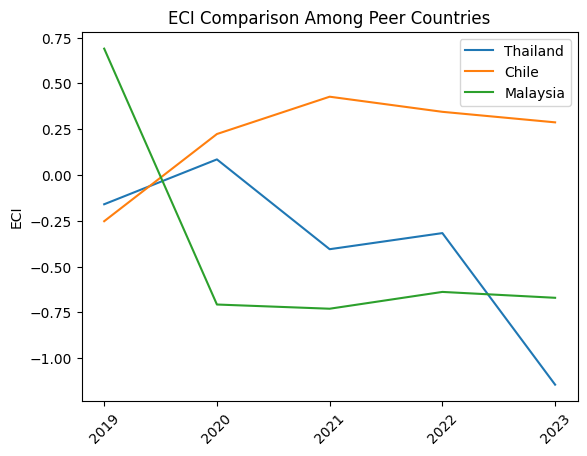

In [31]:
eci_comparison_graph(comparable_countries)

In [32]:


# this is eci_change
#TO FIX - country names + more descriptive file?
#saves output as txt file


with open('comparable_countries_eci_19to21_dict.txt', 'w') as f:
    for country_name in comparable_countries:
        if country_name == 'France':
            country_name = 'France, Monaco'
        elif country_name == "Korea, Rep.":
            country_name = 'Republic of Korea'
        f.write(country_name + '\n')
        f.write(str(round((eci_19to21_dict[country_name][len(eci_19to21_dict[country_name])-1][1]-eci_19to21_dict[country_name][0][1])/abs(eci_19to21_dict[country_name][0][1]) * 100,2)) + '\n')




In [33]:
eci_19to21_dict


defaultdict(list,
            {'Botswana': [(2019, np.float64(-2.07225170837216)),
              (2020, np.float64(1.8560666438497249)),
              (2021, np.float64(1.5256171144639226)),
              (2022, np.float64(1.4113634800203898)),
              (2023, np.float64(2.001952419679043))],
             'Libya': [(2019, np.float64(-1.9807636571419198))],
             'United Arab Emirates': [(2019, np.float64(-1.9807636571419198)),
              (2020, np.float64(1.8617051561514968)),
              (2021, np.float64(1.8667074268722739)),
              (2022, np.float64(1.7094187623818715)),
              (2023, np.float64(2.001952419679043))],
             'Angola': [(2019, np.float64(-1.9807636571419183)),
              (2020, np.float64(1.8617051561514957)),
              (2021, np.float64(1.8667074268722712)),
              (2022, np.float64(1.7094187623818722)),
              (2023, np.float64(0.7526177805086062))],
             'Montserrat': [(2019, np.float64(-1.8892756059

In [34]:
## To FIX
def eci_change(cns):
  for country_name in cns:
    if country_name == 'France':
      country_name = 'France, Monaco'
    elif country_name == "Korea, Rep.":
      country_name = 'Republic of Korea'

    print(country_name)
    print(round((eci_19to21_dict[country_name][len(eci_19to21_dict[country_name])-1][1]-eci_19to21_dict[country_name][0][1])/abs(eci_19to21_dict[country_name][0][1]) * 100,2))

#ok to double print output here

eci_change(comparable_countries)

Thailand
-617.72
Chile
214.16
Malaysia
-197.11


In [35]:

# TO FIX - need an actual ECI Value
[print(x)  for x in eci_19to21_dict[country_name]]

(2019, np.float64(0.6900087948921942))
(2020, np.float64(-0.7067622417999494))
(2021, np.float64(-0.7297280803850412))
(2022, np.float64(-0.6379773692066009))
(2023, np.float64(-0.6700834208533405))


[None, None, None, None, None]

GDP Growth and ECI Trend Graph

In [36]:
## ## UPDATED - MD:
def gdp_and_eci_graph(country_name):
  if country_name=='Vietnam': #not sure if some other names should be changed too
    country_name='Viet Nam'
  elif country_name == 'France':
    country_name = 'France, Monaco'

  fig, ax1 = plt.subplots()

  ax1.set_ylabel('GDP in USD (billions)')
  x_values = [x[0] for x in gdp_range_dict[country_name]]
  y_values = [float(x[1])/(10**9) for x in gdp_range_dict[country_name]]
  # Create the plot
  ax1.xaxis.set_major_locator(MultipleLocator(1))
    # Ensure that tick marks on the x-axis are integers
    #ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x_values, _: int(x_values)))
  ax1.tick_params(axis='x', rotation=45)
  ax1.plot(x_values, y_values, color = 'red', label='GDP')

  # Set the tick labels to custom values, '' added for consistent labeling
  #!!! function to label graph years consistent w/ x_values - JZ
  """ ticklabels = ['', x_values[0]]
    for x in x_values[1:]:
      ticklabels.append('')
      ticklabels.append('')
      ticklabels.append('')
      ticklabels.append('x')
    ticklabels.append('')
    ax1.set_xticklabels(ticklabels)"""
  #ax1.set_xticklabels(['', '2019','','','','2020','','','','2021',''])
  ax1.legend(loc = 'upper left')

  ax2 = ax1.twinx()
  ax2.set_ylabel('ECI')
  #!!! EDITED below because num of ECI values != num of GDP values b/c data
  #!!! only using years in both ECI and GDP - JZ
  def Convert(tup, di):
    di = dict(tup)
    return di
  dictionary = {}
  country_dict = (Convert(eci_19to21_dict[main_country], dictionary))
  ax2.plot(x_values,[country_dict[int(x)] for x in x_values], color = 'blue', label='ECI')

  #ax2.plot(x_values,[x[1] for x in eci_19to21_dict[country_name]], color = 'blue', label='ECI')
  ax2.legend(loc = 'upper right')
  plt.title('GDP and ECI Trend for ' + country_name)
  plt.savefig('drive/My Drive/ECI Auto Report Test/img/kix.kwwogf42gcjl.png')
  plt.show()

In [37]:
gdp_range_dict

{'Aruba': [('2019', 3395793855.0),
  ('2020', 2610038939.0),
  ('2021', 3126019385.0),
  ('2023', 3648573136.0)],
 'Africa Eastern and Southern': [('2019', 1000000000000.0),
  ('2020', 928000000000.0),
  ('2021', 1080000000000.0),
  ('2022', 1170000000000.0),
  ('2023', 1250000000000.0)],
 'Afghanistan': [('2019', 18904502222.0),
  ('2020', 20143451706.0),
  ('2021', 14583135237.0),
  ('2023', 17200000000.0)],
 'Africa Western and Central': [('2019', 823000000000.0),
  ('2020', 786000000000.0),
  ('2021', 844000000000.0),
  ('2022', 878000000000.0),
  ('2023', 799000000000.0)],
 'Angola': [('2019', 69309110146.0),
  ('2020', 50241368244.0),
  ('2021', 65685435100.0),
  ('2022', 107000000000.0),
  ('2023', 84800000000.0)],
 'Albania': [('2019', 15401826081.0),
  ('2020', 15162734205.0),
  ('2021', 17930565119.0),
  ('2022', 18882095518.0),
  ('2023', 23500000000.0)],
 'Andorra': [('2019', 3155149348.0),
  ('2020', 2891001149.0),
  ('2021', 3325145407.0),
  ('2022', 3352032737.0),
  ('20

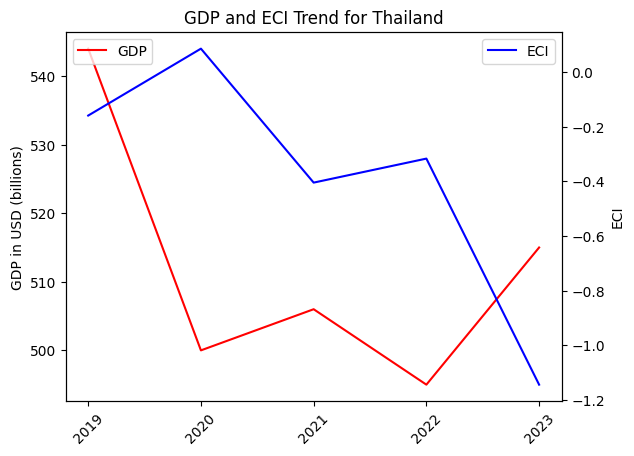

In [38]:
gdp_and_eci_graph(main_country)

## Proximity, Distance, and RID

Proximity

In [39]:
def compute_proximity(mcp,product_sum):
  proximity = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += mcp[k][i] * mcp[k][j]
        except:
          pass
      p0 = product_sum[i]
      p1 = product_sum[j]
      if p0 < p1:
        large = p1
      else:
        large = p0
      product_row.append(temp_sum/large)
    proximity.append(product_row)
  return proximity

Distance

In [40]:
#compute distance
def compute_distance(mcp,proximity):
  distance = []
  for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
      sum1 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum1 += mcp[i][k]*proximity[j][k]
          except:
            pass
      sum2 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum2 += proximity[j][k]
          except:
            pass
      product_row.append(1-sum1/sum2)
    distance.append(product_row)
  return distance

RID

In [41]:
def compute_adi(df_middle,country_list,distance):
  raw_matrix = df_middle.to_numpy()
  matrix = [list(df_middle.columns)]
  for row in raw_matrix:
    if sum(row[1::]) > 0:
      matrix.append(list(row))

  country_list2,product_list2,mcp2,product_sum2,country_sum2 = compute_mcp(matrix)
  proximity2 = compute_proximity(mcp2,product_sum2)
  distance2 = compute_distance(mcp2,proximity2)

  adi = {}
  for i in range(len(country_list)):
    for j in range(len(country_list2)):
      if country_list[i] == country_list2[j]:
        adi[country_list[i]] = np.array(distance2[j]) - np.array(distance[i])
  return adi, country_list2,product_list2

In [42]:
# 18 is equivalent to year 2021
proximity = compute_proximity(mcp,product_sum)
proximity_last_year = compute_proximity(mcp_last_year,product_sum_last_year)

distance = compute_distance(mcp,proximity)
#!!! df_middle changed to df2 because df2 corresponds to df_middle in All Code_v02 - JZ
adi, country_list2,product_list2  = compute_adi(df2,country_list,distance)

In [43]:
#print(adi)

In [44]:
# UPDATED
df_ = pd.DataFrame()
df_['Category'] = product_list_last_year
df_['RID'] = adi[main_country]
df_.sort_values(by="RID", inplace = True)

# Export the DataFrame to an Excel file
filename = main_country + '_RID.xlsx'
df_.to_excel(filename, index=True)
print('ADI results saved to', filename)

ADI results saved to Thailand_RID.xlsx


In [45]:

def style_alternate_rows(x):
    style = ['background-color: lightgrey' if i % 2 == 1 else '' for i in range(len(x))]
    return style

def style_first_column(x):
    return ['color: darkgrey' if i == 0 else 'color: black' for i in range(len(x))]

def style_column_headers(df):
    return [
        {'selector': 'th',
         'props': [('background-color', 'darkgrey'),
                   ('color', 'white'),
                   ('font-weight', 'bold'),
                   ('text-align', 'center'),
                   ('font-family', 'Times New Roman')]},
        {'selector': 'td', 'props': [('font-family', 'Times New Roman')]}
    ]

styled_df = df_.style.apply(style_alternate_rows, axis=0) \
                   .apply(style_first_column, axis=1) \
                   .set_table_styles(style_column_headers(df), overwrite=False, axis=1) \
                   .hide(axis="index")

dfi.export(styled_df, f'/content/drive/My Drive/ECI Auto Report Test/img/kix.fjnsupcfly3m.png', table_conversion='matplotlib')
#would be better without the table_conversion, but that requires running locally

In [46]:
positive_rid_count = (df_['RID'] > 0).sum()
total_rows = len(df_)

if positive_rid_count / total_rows > 0.5:
  jsonout["[Industry development]"] = "progressed"
else:
  jsonout["[Industry development]"] = "regressed"

In [47]:
#leading countries TO DO optional:

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year
for count in sdv_leading_countries:
  df_comp[count + ' RID'] = adi[count]

df_comp.sort_values(by = sdv_leading_countries[0] + ' RID', inplace = True)
# Export the DataFrame to an Excel file
filename = 'sdv_leading_countries_RID1.xlsx'
df_comp.to_excel(filename, index=True)
print('RID results saved to', filename)

RID results saved to sdv_leading_countries_RID1.xlsx


In [48]:
#emerging countries TO DO optional:

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year

for count in sdv_emerging_countries:
  df_comp[count + ' RID'] = adi[count]

df_comp.sort_values(by = sdv_emerging_countries[0] + ' RID', inplace = True)
# Export the DataFrame to an Excel file
filename = 'sdv_emerging_countries_RID2.xlsx'
df_comp.to_excel(filename, index=True)
print('RID results saved to', filename)

RID results saved to sdv_emerging_countries_RID2.xlsx


In [49]:
# UPDATED - for multiple countries with the main country

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year

for count in sdv_comparable_countries:
  df_comp[count + ' RID'] = adi[count]
  print(count)
  print(eci_19to21_dict[count])

df_comp.sort_values(by = main_country + ' RID', inplace=True)
# Export the DataFrame to an Excel file
filename = 'more_countries_RID3.xlsx'
df_comp.to_excel(filename, index=True)
print('RID results saved to', filename)

Thailand
[(2019, np.float64(-0.15942499834767182)), (2020, np.float64(0.0854458346320446)), (2021, np.float64(-0.4048040800150207)), (2022, np.float64(-0.31692006564348424)), (2023, np.float64(-1.1442283777120366))]
Greece
[(2019, np.float64(-0.4284880757891627)), (2020, np.float64(0.14045634938634888)), (2021, np.float64(0.2484479923670391)), (2022, np.float64(0.1958597346395562)), (2023, np.float64(0.043211805749079915))]
Poland
[(2019, np.float64(0.9754848611026912)), (2020, np.float64(-0.3702688221434602)), (2021, np.float64(-0.21523625772437702)), (2022, np.float64(-0.5763359824100462)), (2023, np.float64(-0.6831554161287816))]
Portugal
[(2019, np.float64(0.6195291988979983)), (2020, np.float64(-0.2444410069858014)), (2021, np.float64(0.09882291922021179)), (2022, np.float64(-0.2187032136588722)), (2023, np.float64(-0.13001401380558594))]
France, Monaco
[(2019, np.float64(0.9431860439468899)), (2020, np.float64(-0.8359146357202619)), (2021, np.float64(-0.8223574447451378)), (2022,

In [50]:
df_comp

,Category,Thailand RID,Greece RID,Poland RID,Portugal RID,"France, Monaco RID"
0,Animals and By-products,-0.436124,0.089444,0.010324,-0.050616,0.112775
8,Clothing and Accessories,-0.366881,0.042084,-0.004020,-0.072813,0.076853
15,Precious Stones\t,-0.355473,0.059945,0.045643,-0.053150,0.167383
3,Energy Drilling and Mining,-0.317546,0.034927,0.010724,-0.149201,0.187242
6,Raw Manufacturing,-0.301390,0.024925,0.013083,-0.145943,0.189508
7,Wood Products,-0.286393,-0.018796,0.022015,-0.055406,0.155082
13,Weapons,-0.285580,0.082586,0.013521,-0.058610,0.087008
11,Machinery and Construction,-0.285442,0.034219,-0.093127,-0.162588,0.145679
10,Metals,-0.277343,0.038266,0.001191,-0.060893,0.100254
17,Services and Utilities,-0.272670,0.048754,0.057817,-0.083338,0.254304


## Sequential Strategy

Opportunity Gain

In [51]:
#compute opportunity gain
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        country_row.append(gain)
      #country_row.append(gain)
    opportunity_gain.append(country_row)

  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

Marginal Opportunity Gain

In [52]:
#computes marginal opportunity gain
def compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix):
  marginal = []
  total_sum = np.sum(product_sum)
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        export = matrix[i+1][j+1]
        country_export = country_sum[i]
        product_export = product_sum[j]
        export_increase = (product_export*country_export/total_sum)-export
        country_row.append(opportunity_gain[i][j]*export/export_increase)
    marginal.append(country_row)

  marginal = np.array(marginal)
  return marginal

In [53]:
opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_last_year,proximity_last_year,pci_last_year)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)

#for i in range(len(country_list)):
#  print(country_list[i],opportunity_gain[i])

In [54]:
# For computation of sequential strategies, refer to sequential strategy.py

In [55]:
# For sensitivity analysis, refer to sensitivity.ipynb

In [56]:
# For computation of SOI, soi.ipynb

## SDV & SIDS

In [57]:
import dataframe_image as dfi

# returns a matrix of data read from a csv with the inputed filename
def read_country(filename):
    f = open(filename,'r', encoding='utf-8')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix

# takes a dictionary of scores as input and returns a list of items sorted in descending order based on their scores
def rank(score_dict):
    rank_list = []
    score_list = []
    for item in score_dict:
        score_list.append(score_dict[item])
    while score_list:
        maximum = max(score_list)
        for item in score_dict:
            if score_dict[item] == maximum:
                rank_list.append(item)
        score_list = [score for score in score_list if score!= maximum]
    return rank_list


def sdv_and_sids(country, year):

    wfile = "/content/drive/My Drive/Copy of sdv_and_sids" + country +  ".txt"
    print(wfile)
    #Read the raw matrix
    raw_matrix = read_country(f"{year}.csv")
    raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]
    raw_matrix[19][3] = raw_matrix[19][3]
    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])

    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))

    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    print(product_list)
    print(country_list)

    mcp = []

    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)

    #compute mpp
    country_sum2 = []
    for i in range(0,len(mcp)):
        country_sum2.append(np.sum(mcp[i]))

    product_sum2 = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum2.append(product)

    mpp = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                except:
                    pass
            product_row.append(temp_sum)
        mpp.append(product_row)

    #compute PCI
    mpp = np.array(mpp)

    e_vals, e_vecs = LA.eig(mpp)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)

    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])

    pci = []
    if vector[len(vector)-2] > 0:
        for item in vector:
            pci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            pci.append((-item+np.mean(vector))/np.std(vector))

    #compute proximity
    proximity = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += mcp[k][i] * mcp[k][j]
                except:
                    pass
            p0 = product_sum2[i]
            p1 = product_sum2[j]
            if p0 < p1:
                large = p1
            else:
                large = p0
            product_row.append(temp_sum/large)
        proximity.append(product_row)

    #compute actual distance
    distance = []
    for i in range(0,len(mcp)):
        product_row = []
        for j in range(0,len(mcp[0])):
            sum1 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum1 += (1-mcp[i][k])*proximity[j][k]
                except:
                    pass
            sum2 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum2 += proximity[j][k]
                except:
                    pass
            if mcp[i][j] == 1:
                product_row.append(0)
            else:
                product_row.append(sum1/sum2)
        distance.append(product_row)

    #compute opportunity gain
    opportunity_gain = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            gain = 0
            for k in range(0,len(mcp[0])):
                temp = 0
                for l in range(0,len(mcp[0])):
                    temp += proximity[l][k]
                gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
            gain = gain - (1-distance[i][j]) * pci[j]
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                country_row.append(gain)
        opportunity_gain.append(country_row)

    #compute marginal opportunity gain
    marginal = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                export = raw_matrix[i+1][j+1]
                country_export = country_sum[i]
                product_export = product_sum[j]
                export_increase = (product_export*country_export/total_sum)-export
                country_row.append(opportunity_gain[i][j]*country_export/export_increase)
        marginal.append(country_row)


    #computing sequential strategy
    strategy = []

    for i in range(0,len(country_list)):
        if country in country_list[i]:
            country_index = i
    og = np.copy(opportunity_gain[country_index])
    sdv = dict(zip(product_list, og))
    sdv = sorted(sdv.items(), key=operator.itemgetter(1), reverse=True)
    sdv_colors = []
    for i in range(len(sdv)):
        if sdv[i][1]>0:
          sdv_colors.append(44)
        elif sdv[i][1]==0:
          sdv_colors.append(27)
        else:
          sdv_colors.append(1)
    print("Before Iteration: ")
    writer = open(wfile, 'w')
    writer.write("Before Iteration: ")
    for i in range(0,len(marginal[country_index])):
        write_str = product_list[i] + ": " + str(marginal[country_index][i]) +" \n"

        writer.write(write_str)
        print(product_list[i], ": ", marginal[country_index][i])

    writer.write(" \n")
    print(" ")

    temp = []
    temp.append("Before Iteration")
    posi = {}
    zero = []
    nega = {}
    colors = []
    color = [1]
    for i in range(0,len(marginal[country_index])):
        if marginal[country_index][i] > 0:
            posi[product_list[i]] = marginal[country_index][i]
        elif marginal[country_index][i] == 0:
            zero.append(product_list[i])
        else:
            nega[product_list[i]] = marginal[country_index][i]
    posi = rank(posi)
    nega = rank(nega)
    temp.extend(posi)
    color.extend([44 for i in range(len(posi))])
    temp.extend(zero)
    color.extend([27 for i in range(len(zero))])
    temp.extend(nega)
    color.extend([1 for i in range(len(nega))])
    strategy.append(temp)
    colors.append(color)

    ite_round = 0
    prev_industry = []

    while max(marginal[country_index]) > 0 and ite_round < 20:
        ite_round += 1

        value = max(marginal[country_index])
        for i in range(0,len(marginal[0])):
            if marginal[country_index][i] == value:
                industry_index = i
        industry = product_list[industry_index]
        prev_industry.append(industry_index)

        #calculate new export
        export = raw_matrix[country_index+1][industry_index+1]
        country_export = country_sum[country_index]
        product_export = product_sum[industry_index]
        required_export = product_export*country_export/total_sum
        export_increase = required_export-export

        print("increase ", industry, " in ", country, " by ", export_increase, " USD")
        write_str = "increase "+ industry + " in "+ country + " by "+ str(export_increase) + " USD" +" \n"

        writer.write(write_str)

        raw_matrix[country_index+1][industry_index+1] = required_export*1.3

        #calculate everything again
        country_sum = []
        for i in range(1,len(raw_matrix)):
            country_sum.append(np.sum(raw_matrix[i][1::]))

        product_sum = []
        for i in range(1,len(raw_matrix[0])):
            product = 0
            for j in range(1,len(raw_matrix)):
                product += raw_matrix[j][i]
            product_sum.append(product)
        total_sum = np.sum(product_sum)

        mcp = []

        for i in range (1,len(raw_matrix)):
            country_row = []
            for j in range(1,len(raw_matrix[i])):
                percentage = raw_matrix[i][j]/country_sum[i-1]
                total_percentage = product_sum[j-1]/total_sum
                if percentage > total_percentage:
                    country_row.append(1)
                else:
                    country_row.append(0)
            mcp.append(country_row)

        #compute mpp
        country_sum2 = []
        for i in range(0,len(mcp)):
            country_sum2.append(np.sum(mcp[i]))

        product_sum2 = []
        for i in range(0,len(mcp[0])):
            product = 0
            for j in range(0,len(mcp)):
                product += mcp[j][i]
            product_sum2.append(product)

        mpp = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                    except:
                        pass
                product_row.append(temp_sum)
            mpp.append(product_row)

        #compute PCI
        mpp = np.array(mpp)

        e_vals, e_vecs = LA.eig(mpp)
        eigenvectors = e_vecs.tolist()
        eigen = []
        for eigenvector in eigenvectors:
            temp = []
            for col in eigenvector:
                temp.append(col.real)
            eigen.append(temp)

        vector = []
        for i in range(0,len(eigen)):
            vector.append(eigen[i][1])

        pci = []
        if vector[len(vector)-2] > 0:
            for item in vector:
                pci.append((item-np.mean(vector))/np.std(vector))
        else:
            for item in vector:
                pci.append((-item+np.mean(vector))/np.std(vector))

        #compute proximity
        proximity = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += mcp[k][i] * mcp[k][j]
                    except:
                        pass
                p0 = product_sum2[i]
                p1 = product_sum2[j]
                if p0 < p1:
                    large = p1
                else:
                    large = p0
                product_row.append(temp_sum/large)
            proximity.append(product_row)

        #compute actual distance
        distance = []
        for i in range(0,len(mcp)):
            product_row = []
            for j in range(0,len(mcp[0])):
                sum1 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum1 += (1-mcp[i][k])*proximity[j][k]
                    except:
                        pass
                sum2 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum2 += proximity[j][k]
                    except:
                        pass
                if mcp[i][j] == 1:
                    product_row.append(0)
                else:
                    product_row.append(sum1/sum2)
            distance.append(product_row)

        #compute opportunity gain
        opportunity_gain = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                gain = 0
                for k in range(0,len(mcp[0])):
                    temp = 0
                    for l in range(0,len(mcp[0])):
                        temp += proximity[l][k]
                    gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
                gain = gain - (1-distance[i][j]) * pci[j]
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    country_row.append(gain)
            opportunity_gain.append(country_row)

        #compute marginal opportunity gain
        marginal = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    export = raw_matrix[i+1][j+1]
                    country_export = country_sum[i]
                    product_export = product_sum[j]
                    export_increase = (product_export*country_export/total_sum)-export
                    country_row.append(opportunity_gain[i][j]*country_export/export_increase)
            marginal.append(country_row)

        print("Iteration ", ite_round, ": ")
        write_str = "Iteration "+ str(ite_round)+ ": " + " \n"


        writer.write(write_str)
        for i in range(0,len(marginal[country_index])):
            write_str = product_list[i]+ ": "+ str(marginal[country_index][i])+ " \n"
            print(product_list[i], ": ", marginal[country_index][i])

            writer.write(write_str)
        print(" ")

        writer.write(" \n")

        temp = []
        string = "Iteration " + str(ite_round)
        temp.append(string)
        posi = {}
        zero = []
        nega = {}
        color = [1]
        for i in range(0,len(marginal[country_index])):
            if marginal[country_index][i] > 0:
                posi[product_list[i]] = marginal[country_index][i]
            elif marginal[country_index][i] == 0:
                zero.append(product_list[i])
            else:
                nega[product_list[i]] = marginal[country_index][i]
        posi = rank(posi)
        nega = rank(nega)
        temp.extend(posi)
        color.extend([44 for i in range(len(posi))])
        temp.extend(zero)
        color.extend([27 for i in range(len(zero))])
        temp.extend(nega)
        color.extend([1 for i in range(len(nega))])
        strategy.append(temp)
        colors.append(color)

    strategy = np.array(strategy)
    strategy = np.transpose(strategy)
    colors = np.array(colors)
    colors = np.transpose(colors)
    #print(f'color shape is {colors.shape}')

    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(strategy)):
        for j in range(len(strategy[0])):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = colors[i][j]
          sheet1.write(i,j,strategy[i][j], st)
    book.save(f'sequential strategy of {country}.xls')

    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(sdv)):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = sdv_colors[i]
          sheet1.write(i, 0, sdv[i][0], st)
    book.save(f'sequential vector of {country}.xls')
    write_str = country + " completed"

    writer.write(write_str)
    writer.close()
    print(f'{country} completed')
    return sdv


def stylehelper(x, df):
  toreturn = []
  for col in df.columns:
    toreturn.append(df.loc[x.name, col])
  return ['background-color: #6d9eeb' if v > 0 else 'background-color: #00ffff' if v == 0 else None for v in toreturn]

## UPDATED - MD:  from here only
# TO DO: update "comparable_countries" below if needed
def main():
  myl = []
  for country in comparable_countries:
    myl.append(sdv_and_sids(country, '/content/drive/My Drive/Copyof2022clean'))

    #NZ: changed path to reflect correct sdv source code



  df1 = pd.DataFrame()
  df2 = pd.DataFrame()
  for i in range(0, len(myl)):
    if myl[i]:
      df1[comparable_countries[i]] = [x[0] for x in myl[i]]
      df2[comparable_countries[i]] = [x[1] for x in myl[i]]

  df1 = df1.style.apply(lambda x: stylehelper(x, df2), axis=1)
  dfi.export(df1, f'/content/drive/My Drive/ECI Auto Report Test/img/kix.hntjod878mme.png', table_conversion='matplotlib')

In [58]:
main()

/content/drive/My Drive/Copy of sdv_and_sidsThailand.txt
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
['Albania', 'Andorra', 'Angola', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Barbados', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Plurinational State of Bolivia', 'Bosnia Herzegovina', 'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cabo Verde', 'Canada', 'Central African Republic', 'Chile', 'China', 'China, Hong Kong Special Administrative Region', 'China, Macao Special Administrative Region', 'Colombia', 'Costa Rica', "Côte d'Ivoire

## SOI

In [59]:
# takes a filename argument as input and reads data from a CSV file with the specified filename and stores (and returns) it in a matrix.
def read_it(filename):
    f = open(filename,'r', encoding='cp1252')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                #print(row[i])
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix



In [60]:
zzz+=1
#reads in adi, two county lists and their respective product lists,and opportunity gain: a list of lists that store the opportunity gain for each country and product combination
#outputs a dictionary SOI that contains the SOI values of each country that is in common with country_list and country_list2
def compute_soi_adi(adi, country_list, product_list, country_list2, product_list2, opportunity_gain):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in adi.keys():
          if country_list[i] in country_list2:
              for j in range(0,len(country_list2)):
                  if country_list[i] == country_list2[j]:
                      dependent = adi[country_list[i]]
                      independent = []
                      for item in opportunity_gain[i]:
                          independent.append(item)
                      dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                      model = smf.ols(formula='D ~ I', data=dfs).fit()
                      r_2 = model.rsquared_adj
                      plt.scatter(independent, dependent)
                      #plt.show()
                      #print(model.cov_HC0)
                      #print(country_list[i], "!!!")
                      #print(country_list2[j], "???")
                      common.append(country_list[i])
                      soi[country_list[i]] =r_2
 #TO FIX PATH
    matrix = open('/content/drive/My Drive/Copy of structual optimality index adi ("+str(zzz)+ ").csv','w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in range(0,len(soi)):
       temp = [common[i],soi[common[i]]]
       writer.writerow(temp)
    matrix.close()
    return soi

In [61]:
# compute the SOI for a list of countries and products based on their opportunity gain.
def compute_soi_oppgain(country_list, product_list,country_list2, product_list2, opportunity_gain, opportunity_gain2):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    independent=[]
                    dependent=[]
                    for item in opportunity_gain2[j]:
                        #dependent.append([item])
                        dependent.append(item)
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    # reg = LinearRegression()
                    # reg.fit(independent, dependent)
                    # r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
 #TO FIX PATH
    matrix = open("/content/drive/My Drive/Copy of structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [62]:
#he function calculates the SOI for each country based on its relationship between
# changes in export values (exp_change) and opportunity gain (opportunity_gain)
def compute_soi_exp(country_list, product_list,country_list2, product_list2, opportunity_gain, exp_change):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = []
                    independent = []
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    #print(opportunity_gain2[i])
                    for item in exp_change.loc[country_list[i],:]:
                        #dependent.append([item])
                        dependent.append(item)
                    #reg = LinearRegression()
                    #reg.fit(independent, dependent)
                    #r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I':independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    soi[country_list[i]] = r_2
  #TO FIX PATH
    matrix = open(root_path+"structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [63]:
# TO FIX years
# Issue with SOI in here: common2, independent, and dependent are all empty
# so model = smf.ols(formula='GDP ~ SOI', data=dfs).fit() throws a ValueError

def compute_regress(soi, gdp_raw, country_list, country_list2):
    #comprehensive regression
    common=np.intersect1d(list(soi.keys()), gdp_raw.index.to_list())
    independent = []
    dependent = []

    growth = {}

    for country in common:
      independent.append(soi[country])

      grwth = (gdp_raw.loc[country, '2021'] - gdp_raw.loc[country, '2019']) / gdp_raw.loc[country, '2019']
      dependent.append(grwth)
      growth[country] = grwth

    dfs=  pd.DataFrame({'Country': common,'GDP':dependent, 'SOI': independent})
    #dfs.set_index('Country', inplace=True)

    model = smf.ols(formula='GDP ~ SOI', data=dfs).fit()


    fig = px.scatter(dfs, x="SOI", y="GDP", trendline="ols")
    fig.update_layout(
    yaxis_title="% Growth in GDP 2019-2021",
    xaxis_title="SOI",
    height=600,
    width=900,
    title_x=.5,
    font=dict(
        family="Times New Roman",
        size=15
        ) )
    #fig.update_traces(textposition='top center')
    fig2 = plt.figure(figsize=(12,8))
    fig2 = sm.graphics.plot_regress_exog(model,'SOI', fig=fig2)
    fig3, ax = plt.subplots(figsize=(12,8))
    fig3 = sm.graphics.influence_plot(model, ax=ax, criterion='Cooks')
    fig_name = "Regression of GDP over SOI.png"
    #fig.savefig(fig_name)
    #pio.write_image(fig, fig_name)
    fig.write_image(fig_name, engine="kaleido")
    fig.write_image('/content/drive/My Drive/ECI Auto Report Test/img/kix.cqwj8nwgoqtv.png', engine="kaleido")
    fig.show()
    return model, growth

In [64]:
# computes opportunity gain

  # computes opportunity gain
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      country_row.append(gain)
    opportunity_gain.append(country_row)

  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain





In [65]:

opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_last_year,proximity_last_year,pci_last_year)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)

In [66]:
# Creates a scatter plot of the opportunity_gain and the adi for a specific country

def soi_plotter(country, adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    if len(product_list) == len(product_list2):
            print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2 and country_list[i]==country:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)

                    #print(dependent)
                    #print(np.array(independent))

                    # print(product_list)
                    # Create figure with secondary y-axis
                    fig = make_subplots(specs=[[{"secondary_y": True}]])

                    # Add traces
                    fig.add_trace(
                        go.Scatter(x=product_list, y=independent, name="Opportunity Gain"),
                        secondary_y=False,
                    )

                    fig.add_trace(
                        go.Scatter(x=product_list, y=dependent, name="RID"),
                        secondary_y=True,
                    )

                    # Add figure title
                    fig.update_layout(
                        title_text="SOI of "+country
                    )
                    fig.update_layout(
                        height=600,
                        width=1500,
                        title_x=.5,
                        font=dict(
                            family="Times New Roman",
                            size=15
                            ) )
                    # Set x-axis title
                    fig.update_xaxes(title_text="Product Category")

                    # Set y-axes titles
                    fig.update_yaxes(title_text="RID", secondary_y=False)
                    fig.update_yaxes(title_text="Opportunity Gain", secondary_y=True)




                    correlation_matrix = np.corrcoef(dependent, independent)
                    correlation_xy = correlation_matrix[0,1]
                    r_squared = correlation_xy**2 # soi is adjusted r^2, this is non-adjusted.

                    figure_name = "SOI of "+ country + ".png"
                    #fig.savefig(figure_name)
                    #pio.write_image(fig, figure_name)
                    fig.write_image(figure_name, engine="kaleido")
                    fig.write_image('/content/drive/My Drive/ECI Auto Report Test/img/kix.lcc2qvnzl4s3.png', engine="kaleido")
                    fig.show()




###SOI w/ ADI

categorization verified


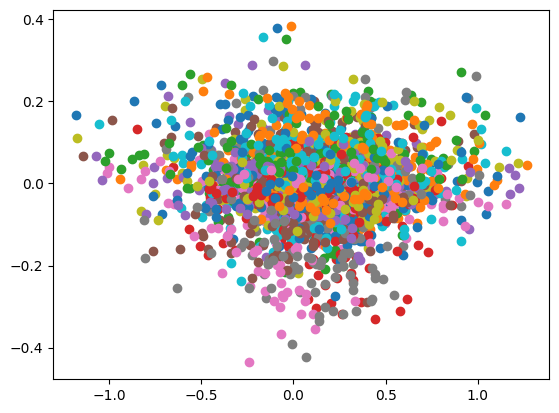

In [67]:

all_country_soi = compute_soi_adi(adi, country_list, product_list,country_list, product_list2, opportunity_gain)
sorted_soi = sorted(all_country_soi.items(), key=operator.itemgetter(1))
soi_rank = sorted_soi.index((main_country, all_country_soi[main_country])) + 1

In [68]:
soi_pctl = soi_rank / len(sorted_soi)

if soi_pctl < 0.25:
  jsonout['[SOI quartile]'] = 'bottom'
  jsonout['[SOI quality]'] = 'low'
elif soi_pctl < 0.5:
  jsonout['[SOI quartile]'] = 'second'
  jsonout['[SOI quality]'] = 'moderate'
elif soi_pctl < 0.75:
  jsonout['[SOI quartile]'] = 'third'
  jsonout['[SOI quality]'] = 'moderate'
else:
  jsonout['[SOI quartile]'] = 'top'
  jsonout['[SOI quality]'] = 'high'

jsonout['[SOI]'] = all_country_soi[main_country]

0.012326746018551216
0.003662945545029661
1.422787384846241
0.23542189042438527
116.0


'soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)\nsoi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))\n\n#UPDATED - GDP4 needed other reworks\n\ngdp_raw = gdp_df.fillna(0)\n\nreg, growth = compute_regress(soi_adi, gdp_raw, country_list, country_list2)\n\n# print(len(country_list))\n# print(len(country_list2))\n# print(len(soi_adi_list))\nreg.summary()'

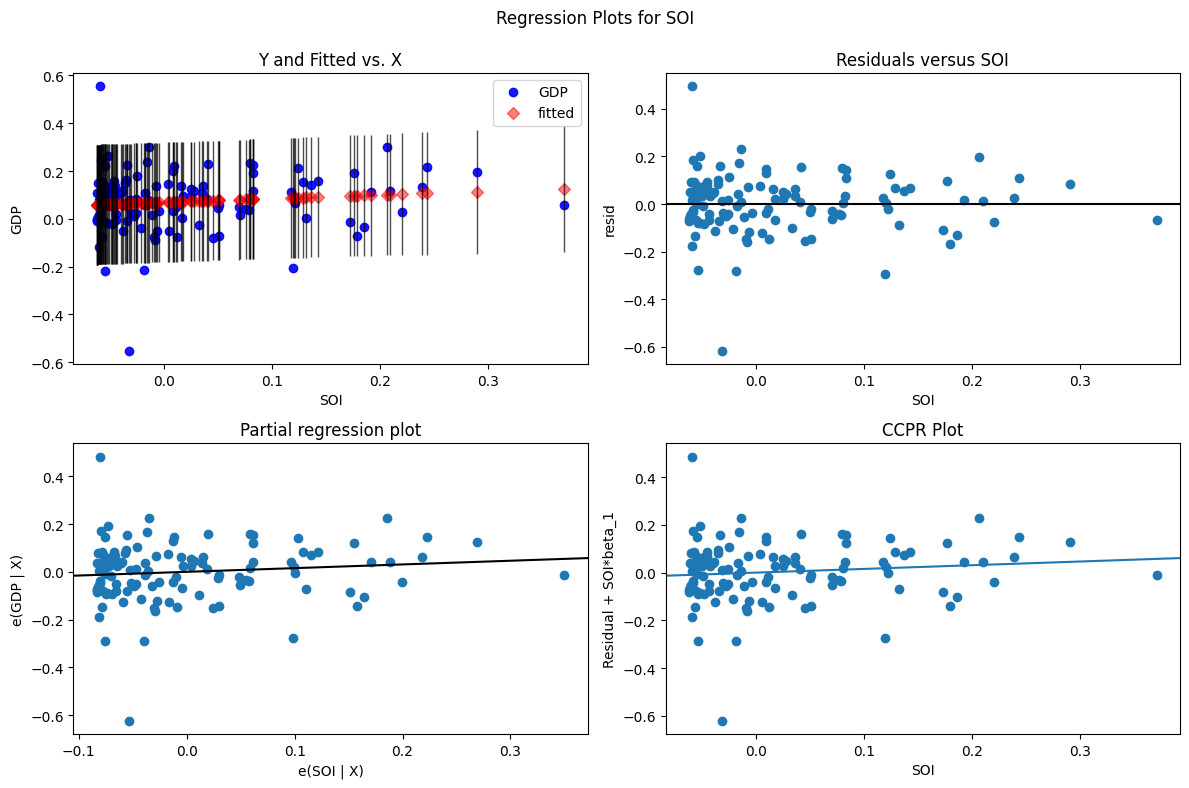

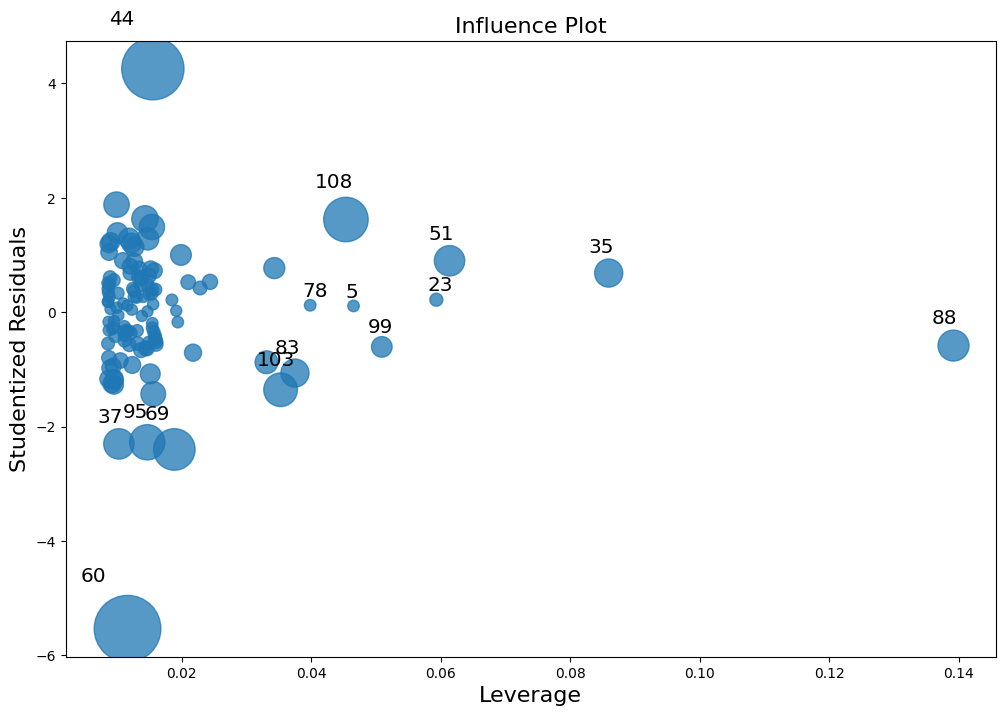

In [69]:


#gdp_raw=pd.read_csv(GDP4_path+'/GDP4.csv', index_col=0).fillna(0) #File path updated - JZ
gdp_raw=gdp_df.fillna(0)
gdp_raw.set_index('Country', inplace=True)
#pd.read_csv(path_to_data+'GDP_2022.csv', index_col=0).fillna(0) #NZ: Change to GDP_2022

reg, growth = compute_regress(all_country_soi, gdp_raw, country_list, country_list2)

jsonout['[R^2]'] = reg.rsquared
jsonout['[R^2 adj]'] = reg.rsquared_adj
jsonout['[F-Stat]'] = reg.fvalue
jsonout['[Prob]'] = reg.f_pvalue
jsonout['[nobs]'] = reg.nobs

print(reg.rsquared)
print(reg.rsquared_adj)
print(reg.fvalue)
print(reg.f_pvalue)
print(reg.nobs)

reg.summary()

"""soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)
soi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))

#UPDATED - GDP4 needed other reworks

gdp_raw = gdp_df.fillna(0)

reg, growth = compute_regress(soi_adi, gdp_raw, country_list, country_list2)

# print(len(country_list))
# print(len(country_list2))
# print(len(soi_adi_list))
reg.summary()"""

In [70]:
# IMPORTANT. RUN THIS TO SAVE JSON.

import json

if jsonout["[GDP growth quality]"] == "high" and jsonout["[ECI growth quality]"] == "increased":
  jsonout["[Overall quality]"] = "positive"
  jsonout["[Strategy quality]"] = "improved"
elif jsonout["[GDP growth quality]"] == "low" and jsonout["[ECI growth quality]"] == "decreased":
  jsonout["[Overall quality]"] = "negative"
  jsonout["[Strategy quality]"] = "declining"
else:
  jsonout["[Overall quality]"] = "mixed"
  jsonout["[Strategy quality]"] = "stagnant"


with open(jsonpath, 'w') as f:
    json.dump(jsonout, f, indent=4)

In [71]:
c= main_country
soi_plotter(c, adi, country_list, product_list, country_list2, product_list2, opportunity_gain)
print('SOI', all_country_soi[c],'Growth', growth[c])

categorization verified


SOI 0.17907309655285708 Growth -0.06985294117647059


SOI w/ Opportunity Gain

categorization verified
[('Andorra', np.float64(0.22568176128292228)), ('Angola', np.float64(0.03414299680841104)), ('Antigua and Barbuda', np.float64(-0.04538608817137835)), ('Argentina', np.float64(0.7378624941686927)), ('Armenia', np.float64(0.7080812794272466)), ('Aruba', np.float64(0.46617346693200834)), ('Australia', np.float64(0.7025589261513407)), ('Austria', np.float64(0.37727800053562555)), ('Azerbaijan', np.float64(-0.05469019840952716)), ('Bahamas', np.float64(-0.04341839009466897)), ('Bahrain', np.float64(0.2992726626693667)), ('Barbados', np.float64(0.7226779578364314)), ('Belgium', np.float64(0.8262760284190602)), ('Belize', np.float64(0.8652193435883613)), ('Benin', np.float64(0.6684627575251143)), ('Bermuda', np.float64(0.3841557499520495)), ('Bosnia Herzegovina', np.float64(0.5597370256963119)), ('Botswana', np.float64(0.13725810841553732)), ('Brazil', np.float64(0.04349532339569473)), ('Brunei Darussalam', np.float64(0.0781983765579376)), ('Bulgaria', np.float64(0.20

                            OLS Regression Results                            
Dep. Variable:                    GDP   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.009
Method:                 Least Squares   F-statistic:                   0.05747
Date:                Mon, 26 May 2025   Prob (F-statistic):              0.811
Time:                        13:04:47   Log-Likelihood:                 58.276
No. Observations:                 109   AIC:                            -112.6
Df Residuals:                     107   BIC:                            -107.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0864      0.025      3.510      0.0

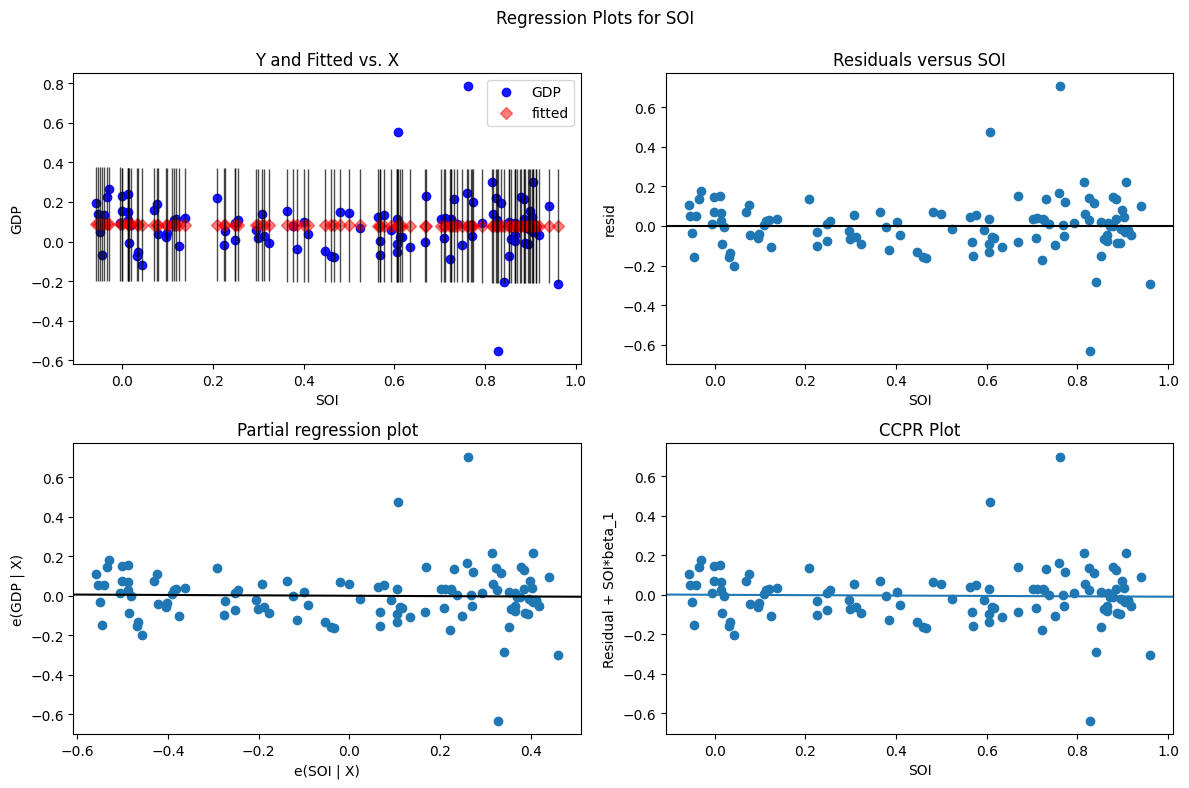

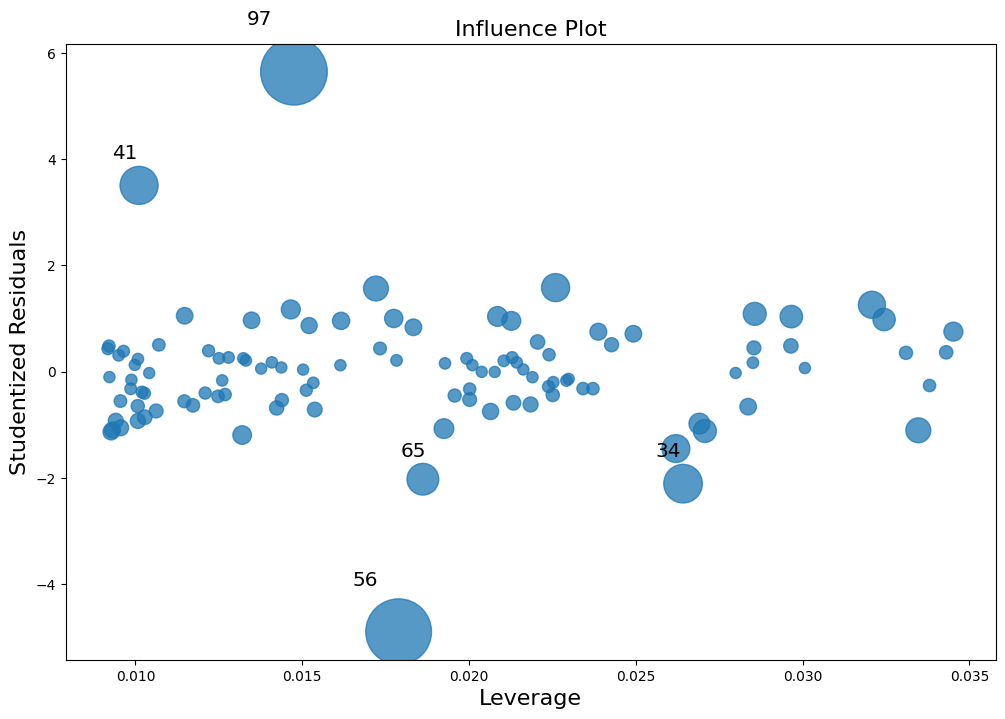

In [72]:
soi_oppg= compute_soi_oppgain(country_list, product_list,country_list_last_year, product_list_last_year, opportunity_gain, opportunity_gain_18)
print(sorted(soi_oppg.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_last_year))
reg_opp= compute_regress(soi_oppg, gdp_raw, country_list, country_list_last_year) #updated "Country Name" key to "Country" - JZ
print(reg_opp[0].summary())

#reg_opp.summary()

In [73]:
gdp_raw

,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,"France, Monaco"
Country,,,,,,,,,,,,,,,,,,,,,
Aruba,7.648045e+08,8.720670e+08,9.586592e+08,1.083240e+09,1.245810e+09,1.320670e+09,1.379888e+09,1.531844e+09,1.665363e+09,1.722905e+09,...,2.963128e+09,2.983799e+09,3.092179e+09,3.276188e+09,3.395794e+09,2.610039e+09,3.126019e+09,0.000000e+00,3.648573e+09,France
Africa Eastern and Southern,2.540000e+11,2.770000e+11,2.460000e+11,2.430000e+11,2.400000e+11,2.700000e+11,2.690000e+11,2.830000e+11,2.670000e+11,2.630000e+11,...,9.270000e+11,8.850000e+11,1.020000e+12,1.010000e+12,1.000000e+12,9.280000e+11,1.080000e+12,1.170000e+12,1.250000e+12,France
Afghanistan,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,1.999814e+10,1.801955e+10,1.889635e+10,1.841886e+10,1.890450e+10,2.014345e+10,1.458314e+10,0.000000e+00,1.720000e+10,France
Africa Western and Central,1.220000e+11,1.180000e+11,1.190000e+11,9.927218e+10,8.663640e+10,1.090000e+11,1.260000e+11,1.280000e+11,1.310000e+11,1.380000e+11,...,7.690000e+11,6.910000e+11,6.850000e+11,7.670000e+11,8.230000e+11,7.860000e+11,8.440000e+11,8.780000e+11,7.990000e+11,France
Angola,1.122952e+10,1.270456e+10,1.511435e+10,1.105194e+10,3.390500e+09,5.561222e+09,7.526964e+09,7.648377e+09,6.506230e+09,6.152923e+09,...,8.721930e+10,4.984049e+10,6.897277e+10,7.779294e+10,6.930911e+10,5.024137e+10,6.568544e+10,1.070000e+11,8.480000e+10,France
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Kosovo,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,6.295845e+09,6.682674e+09,7.180769e+09,7.878763e+09,7.899741e+09,7.717143e+09,9.412034e+09,9.429156e+09,1.050000e+10,France
"Yemen, Rep.",5.647119e+09,5.930370e+09,6.463650e+09,5.368271e+09,4.167356e+09,4.258789e+09,5.785685e+09,6.838557e+09,6.325142e+09,7.641103e+09,...,4.244449e+10,3.131782e+10,2.684223e+10,2.160616e+10,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,France
South Africa,1.260000e+11,1.350000e+11,1.470000e+11,1.470000e+11,1.540000e+11,1.720000e+11,1.630000e+11,1.690000e+11,1.530000e+11,1.520000e+11,...,3.470000e+11,3.240000e+11,3.810000e+11,4.040000e+11,3.890000e+11,3.380000e+11,4.190000e+11,4.060000e+11,3.810000e+11,France


# End of Comprenesive

# 2. Greedy Budget Allocation

This code file takes in a country's economic data and runs a greedy algorithm to maximize its ECI for each budget percentage (5%, 10%, 15%, 20%). Then, the output with all the path increments is saved into a pickle file
#### TO DO:

In [74]:

#TO DO: make sure to create a folder New_result_update in your OWN drive
path = 'drive/My Drive/New_result_update/'

#updated
#root_path = 'drive/My Drive/ECI Research/Fall 2022/Data/2019-2021 cleaned/'
#NZ: Root path updated to reflect 2022:
root_path = 'drive/My Drive/ECI Research/5. Datasets/2023 Fall - Data/2019-2022 cleaned/'


# TO DO: UPDATE to the main country
# main_country = 'Colombia'

In [75]:

#### Import packages
#Install xlwt:
"""!pip install xlwt
Install the kaleido package for exporting images
!pip install -U kaleido"""

#needed to downgrade plotly for kaleido to work; the code seems to run fine with the lower version,
#but let me know if we run into issues
!pip install plotly==5.3.1
import io
import os
import csv
import statsmodels.api as sm
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import operator
import xlwt
import tqdm
import sys, os
import multiprocessing
import plotly.graph_objects as go
import plotly.graph_objects as go
import pickle

from plotly.offline import plot
from plotly.subplots import make_subplots
from xlwt import Workbook
from functools import partial
from scipy import linalg as LA
import copy
from functools import partial
import plotly.graph_objects as go
from plotly.subplots import make_subplots


  Using cached plotly-5.3.1-py2.py3-none-any.whl.metadata (7.4 kB)
Using cached plotly-5.3.1-py2.py3-none-any.whl (23.9 MB)
  Attempting uninstall: plotly
    Found existing installation: plotly 6.1.1
    Uninstalling plotly-6.1.1:
      Successfully uninstalled plotly-6.1.1


### Metrics calculation

#### MCP

In [76]:
# MCP:

def compute_mcp(matrix):
  product_list = matrix[0][1::]
  country_list = []
  for i in range(1,len(matrix)):
    country_list.append(matrix[i][0])

  country_sum = []
  for i in range(1,len(matrix)):
    country_sum.append(np.sum(matrix[i][1::]))

  product_sum = []
  for i in range(1,len(matrix[0])):
    product = 0
    for j in range(1,len(matrix)):
        product += matrix[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcp = []

  for i in range (1,len(matrix)):
    country_row = []
    for j in range(1,len(matrix[i])):
      try:
        percentage = matrix[i][j]/country_sum[i-1]
      except:
        print(country_list[i-1])
      total_percentage = product_sum[j-1]/total_sum
      if percentage > total_percentage:
        country_row.append(1)
      else:
        country_row.append(0)
    mcp.append(country_row)

  return country_list, product_list, mcp, product_sum, country_sum

#### MCC

In [77]:
# MCC:

def compute_mcc(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcc = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp)):
      temp_sum = 0
      for k in range(0,len(mcp[0])):
        try:
          value = (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
          if np.isinf(value) or np.isnan(value):
            temp_sum += 0
          else:
            temp_sum += value
        except:
          pass
      country_row.append(temp_sum)
    mcc.append(country_row)
  return mcc

#### MPP

In [78]:
#MPP:

def compute_mpp(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mpp = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += (mcp[k][i] * mcp2[k][j]/(country_sum[k]*product_sum[i]))
        except:
          pass
      product_row.append(temp_sum)
    mpp.append(product_row)
  return mpp

#### ECI

In [79]:
#### ECI
def compute_eci(mcc):
  mcc = np.array(mcc)

  e_vals, e_vecs = LA.eig(mcc)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  eci = []
  if vector[0] < 0:
    for item in vector:
      eci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      eci.append((-item+np.mean(vector))/np.std(vector))
  return eci

#### PCI

In [80]:
# PCI:

def compute_pci(mpp):
  mpp = np.array(mpp)
  e_vals, e_vecs = LA.eig(mpp)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  pci = []
  if vector[len(vector)-2] > 0:
    for item in vector:
      pci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      pci.append((-item+np.mean(vector))/np.std(vector))
  return pci

#### Proximity

In [81]:
#### Proximity
def compute_proximity(mcp, product_sum):
  proximity = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += mcp[k][i] * mcp[k][j]
        except:
          pass
      p0 = product_sum[i]
      p1 = product_sum[j]
      if p0 < p1:
        large = p1
      else:
        large = p0
      product_row.append(temp_sum/large)
    proximity.append(product_row)
  return proximity

#### Distance

In [82]:

#Distance:

def compute_distance(mcp, proximity):
  distance = []
  for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
      sum1 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum1 += mcp[i][k]*proximity[j][k]
          except:
            pass
      sum2 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum2 += proximity[j][k]
          except:
            pass
      product_row.append(1-sum1/sum2)
    distance.append(product_row)
  return distance

#### Opportunity Gain

In [83]:
#Opportunity Gain:

def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        country_row.append(gain)
      #country_row.append(gain)
    opportunity_gain.append(country_row)

  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain



#### Marginal Oppotunity Gain

In [84]:
#### marginal oppotunity gain
def compute_marginal_opportunity_gain(mcp, opportunity_gain, country_sum,
                                      product_sum, raw_matrix):
  marginal = []
  total_sum = np.sum(product_sum)
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        export = raw_matrix[i+1][j+1]
        country_export = country_sum[i]
        product_export = product_sum[j]
        export_increase = (product_export * country_export / total_sum) - export
        country_row.append(opportunity_gain[i][j] * export / export_increase)
    marginal.append(country_row)

  marginal = np.array(marginal)
  return marginal

### Greedy

In [85]:
def two_step_greedy(country, year, num_part, percentage):

    df = pd.read_csv("/content/drive/My Drive/Copyof" + f'{year}clean.csv')

    raw_matrix = df.to_numpy() # export data with only values

    matrix = [list(df.columns)] # export data with IDs and values

    for row in raw_matrix:
      matrix.append(list(row))

    product_list = matrix[0][1::]
    country_list = []

    for i in range(1,len(matrix)):         # Search country index
        country_list.append(matrix[i][0])

        if country == 'USA' or country == 'France':
            if country in matrix[i][0]:
                country_index = i
                total_export = np.sum(matrix[i][1::])
                print(f'\nCountry: {country}, index is {i}')
        elif country == matrix[i][0]:
            country_index = i
            total_export = np.sum(matrix[i][1::])
            print(f'\nCountry: {country}, index is {i}')

    budget = (percentage/100) * total_export
    share = budget/num_part
    weapon_index = matrix[0].index('Weapons')
    weapon_value = matrix[country_index][weapon_index]

    print(f'Original total export is {total_export}, budget is {budget}, share is {share}, percentage is {budget/total_export*100}%.')
    mcp, product_sum, country_sum = compute_mcp(matrix)[2:]
    mcc = compute_mcc(mcp)
    eci = compute_eci(mcc)
    mpp = compute_mpp(mcp)
    pci = compute_pci(mpp)
    distances = compute_proximity(mcp, product_sum)

    last_eci = eci[country_index-1]
    print(f'ECI this year is {last_eci}')
    original_vector = np.copy(matrix[country_index][1::])

    total = 0
    improvement_index = []
    improvement_percentage = [0]
    eci_increment = [last_eci]
    improved_matrix = copy.deepcopy(matrix)

    while total + 200 < budget:

        print(f'\nProgress: {round(total/budget, 2)}')

        multiplier = 0

        stop_1 = 0
        stop_2 = 0
        budget_reach = 0

        achieved_eci_1 = 0
        achieved_eci_2 = 0

        total_budget_1 = 0
        total_budget_2 = 0

        last_budget = 0

        while stop_1 == 0 or stop_2 == 0:

            if total + share * multiplier + 200 >= budget:

                budget_reach = 1

            else:

                multiplier += 1

            print(f'Path 1: {stop_1}, Path 2: {stop_2}, multiplier: {multiplier}, keep increasing multiplier.')

            eci_temp = []

            matrix_ = copy.deepcopy(improved_matrix)
            for i in range(1, len(matrix[0])):  # make changes on the matrix with data and IDs, index has to start from 1

                matrix_[country_index][i] += share * multiplier
                country_list, product_list, mcp, product_sum, country_sum = compute_mcp(matrix_)
                mcc = compute_mcc(mcp)

                if i == weapon_index:

                    ratio = (matrix_[country_index][weapon_index] - weapon_value)/weapon_value

                    if ratio > 0.1:

                        eci_temp.append((-1)*np.inf)  # The limit of the increment of weapon is 10%
                    else:

                        eci_temp.append(compute_eci(mcc)[country_index - 1])  # index minus 1 because of the matrix without IDs
                else:

                    eci_temp.append(compute_eci(mcc)[country_index - 1])

                matrix_[country_index][i] -= share * multiplier

            if ((max(eci_temp) > last_eci and total + share * multiplier > last_budget)
                or budget_reach) and stop_1 == 0: # Check whether the eci in path 1 has improved

                stop_1 = 1

                if max(eci_temp) > last_eci:

                    print('Path 1 find increments. Stop path 1.')
                    if eci_temp.count(max(eci_temp)) > 1:

                        indices = np.where(np.array(eci_temp) == np.max(eci_temp))[0]
                        max_pci = np.max(np.array(pci)[indices])
                        index_1 = np.where(np.array(pci) == max_pci)[0][0]

                    elif eci_temp.count(max(eci_temp)) == 1:

                        index_1 = np.argmax(eci_temp)

                elif budget_reach:

                    print(f'Total reached {total + share * multiplier}. Path 1 to the end.')
                    mcp, product_sum, country_sum = compute_mcp(improved_matrix)[2:]
                    proximity = compute_proximity(mcp, product_sum)
                    all_distances = compute_distance(mcp, proximity)
                    distances = all_distances[country_index - 1]
                    index_1 = list(distances).index(min(np.array(distances)[np.array(distances)>0]))
                    compute_distance(mcp, proximity)

                achieved_eci_1 = max(eci_temp)
                total_budget_1 = total + share * multiplier
                last_budget = total_budget_1

            if ((max(eci_temp) > achieved_eci_1 and stop_1 == 1)
                or budget_reach) and stop_2 == 0: # Check whether the eci in path 2 has improved

                stop_2 = 1

                if max(eci_temp) > last_eci:

                    print('Path 2 find increments. Stop path 2.')
                    if eci_temp.count(max(eci_temp)) > 1:

                        indices = np.where(np.array(eci_temp) == np.max(eci_temp))[0]
                        max_pci = np.max(np.array(pci)[indices])
                        index_2 = np.where(np.array(pci) == max_pci)[0][0]

                    elif eci_temp.count(max(eci_temp)) == 1:

                        index_2 = np.argmax(eci_temp)

                elif budget_reach:

                    print(f'Total reached {total + share * multiplier}. Path 2 to the end.')
                    mcp, product_sum, country_sum = compute_mcp(improved_matrix)[2:]
                    proximity = compute_proximity(mcp, product_sum)
                    all_distances = compute_distance(mcp, proximity)
                    distances = all_distances[country_index - 1]
                    index_2 = list(distances).index(min(np.array(distances)[np.array(distances)>0]))

                achieved_eci_2 = max(eci_temp)
                total_budget_2 = total + share * multiplier

        print(f'path 1 differnce:{total_budget_1 - total}')
        print(f'path 2 differnce:{total_budget_2 - total}')
        ratio_1 = (achieved_eci_1 - last_eci)/(total_budget_1 - total)
        ratio_2 = (achieved_eci_2 - last_eci)/(total_budget_2 - total)

        if ratio_1 < ratio_2:

            total = total_budget_2
            print(f'Select path 2, total right now is {total}')
            print(f'Path 2 largest argument is {index_2 + 1}, product is {product_list[index_2]}')
            if achieved_eci_2 > last_eci:

              print(f'last ci is {last_eci}, this eci is {achieved_eci_2}')
              last_eci = achieved_eci_2

            else:
              print(f'last ci is {last_eci}, this eci is {last_eci}')

            improved_matrix[country_index][index_2 + 1] += total_budget_2
            improvement_percentage.append(total_budget_2/budget)
            improvement_index.append(index_2 + 1)

        else:

            total = total_budget_1
            print(f'Select path 1, total right now is {total}')
            print(f'Path 1 largest argument is {index_1 + 1}, product is {product_list[index_1]}')

            if achieved_eci_1 > last_eci:

              print(f'last ci is {last_eci}, this eci is {achieved_eci_1}')
              last_eci = achieved_eci_1

            else:
              print(f'last ci is {last_eci}, this eci is {last_eci}')

            improved_matrix[country_index][index_1 + 1] += total_budget_1
            improvement_percentage.append(total_budget_1/budget)
            improvement_index.append(index_1 + 1)

        eci_increment.append(last_eci)

    optimal_allocation = np.round(np.array(improved_matrix[country_index][1::])\
                                  - original_vector, 2)
    max_eci = last_eci

    return dict(zip(product_list,optimal_allocation)), improvement_percentage, \
            eci_increment, total_export, improvement_index


In [86]:
# TO FIX

#This function doesn't seem to be called anywhere; I'm not sure what the use is
def greedy_stablizer(country, year, percentage, num_part):
    num_part = np.linspace(5, 30, num=6)
    result = []
    for part in num_part:
      result.append(two_step_greedy(country, year, percentage, part))
    eci = [i[1] for i in result]
    m = max(eci)
    max_index = [i for i, j in enumerate(eci) if j == m]
    optimal_index = 0
    diversity = sum(1 for i in result[max_index[0]][0].values() if i >= 0)
    for index in max_index:
      if sum(1 for i in result[max_index[index]][0].values() if i >= 0) > diversity:
        optimal_index = index
    return result[optimal_index]

### Plot

In [87]:
def pie_plot(country, allocations):
    labels = []

    target_dir = '/content/drive/My Drive/Will ECI Auto Report Test/img'
    if not os.path.exists(target_dir):
    os.makedirs(target_dir)   # create all intermediate dirs

    print("Saving images to:", target_dir)
    # (Optionally, list its contents so you know what’s there)
    print(os.listdir(target_dir))
    for i in range(len(allocations)):
        allocations[i] = {x:y for x,y in allocations[i].items() if y!=0}
        labels.append(list(allocations[i].keys()))
    specs = [[{'type':'domain'}, {'type':'domain'}, {'type':'domain'}, {'type':'domain'}]]
    fig = make_subplots(rows=1, cols=4, specs = specs)
    fig.add_trace(go.Pie(labels=labels[0], values=np.asarray(list(allocations[0].values()))/np.sum(list(allocations[0].values())),
                         name="5% growth"), 1, 1)
    fig.add_trace(go.Pie(labels=labels[1], values=np.asarray(list(allocations[1].values()))/np.sum(list(allocations[1].values())),
                         name="10% growth"), 1, 2)
    fig.add_trace(go.Pie(labels=labels[2], values=np.asarray(list(allocations[2].values()))/np.sum(list(allocations[2].values())),
                         name="15% growth"), 1, 3)
    fig.add_trace(go.Pie(labels=labels[3], values=np.asarray(list(allocations[3].values()))/np.sum(list(allocations[3].values())),
                         name="20% growth"), 1, 4)

    # Use `hole` to create a donut-like pie chart
    fig.update_traces(hole=.4, hoverinfo="label+percent+name")

    fig.update_layout(
        title_text=f"{country} ECI Growth Optimization Result",
        # Add annotations in the center of the donut pies.
        font=dict(
        family="Times New Roman"),
        annotations=[dict(text='5', x=0.095, y=0.5, font_size=20, showarrow=False),
                     dict(text='10', x=0.37, y=0.5, font_size=20, showarrow=False),
                     dict(text='15', x=0.63, y=0.5, font_size=20, showarrow=False),
                     dict(text='20', x=0.91, y=0.5, font_size=20, showarrow=False)])
    #fig.update_layout(margin=dict(t=50, b=0, l=0, r=0))
    fig.write_image('/content/drive/My Drive/ECI Auto Report Test/img/kix.qkzmpvrz2v9z.png', engine="kaleido")
    fig.show()

def eic_growth_plot(country, eci_increment):
    trace1 = go.Scatter(x = list(range(0, len(eci_increment[0]))),
                         y = eci_increment[0], name="5% growth",
                        line=dict(width=6),marker=dict(size=15))

    trace2 = go.Scatter(x = list(range(0, len(eci_increment[1]))), xaxis="x2",
                         y = eci_increment[1], name="10% growth",
                        line=dict(width=6), marker=dict(size=15))

    trace3 = go.Scatter(x = list(range(0, len(eci_increment[2]))), xaxis="x3",
                         y = eci_increment[2], name="15% growth",
                        line=dict(width=6), marker=dict(size=15))

    trace4 = go.Scatter(x = list(range(0, len(eci_increment[3]))), xaxis="x4",
                         y = eci_increment[3], name="20% growth",
                        line=dict(width=6), marker=dict(size=15))

    data = [trace1, trace2, trace3, trace4]

    layout = go.Layout(
        xaxis=dict(
            domain=[0, 0.25]
        ),
        legend=dict(
            traceorder="reversed"
        ),
        xaxis2=dict(
            domain=[0.25, 0.5]
        ),
        xaxis3=dict(
            domain=[0.5, 0.75]
        ),
        xaxis4=dict(
            domain=[0.75, 1]
        ),
        title_text=f"{country} ECI Growth",
        font=dict(
        family="Times New Roman")

    )
    fig = go.Figure(data=data, layout=layout)
    fig.update_layout(height=400, width=900, title_text=f"{country} ECI Increment", showlegend=True)
    fig.write_image('/content/drive/My Drive/ECI Auto Report Test/img/kix.u68suuv7ge1c.png', engine="kaleido")
    fig.show()

### Running Greedy:

In [88]:
# TO FIX: add "loud" so htat we don't print but also make for loops into a funciton

In [89]:
#Running Greedy Below:
# 5%
# This algo runs for a while (~25min)

# Make sure path points to the right place under your mounted Drive:
path = '/content/drive/My Drive/New_result_update/'

# Create the folder if it doesn’t exist:
os.makedirs(path, exist_ok=True)

country = main_country
year = end_year
num_share = [30, 60, 90, 120]
budget_percentage = [5] # Run for percentages of: [5,10,15,20]

all_result = []
all_allocations = []
all_eci_increments = []
#Running two-step greedy:

for iter, budget in enumerate(budget_percentage):

    result = two_step_greedy(country, year, num_share[iter], budget)
    allocation = result[0]
    eci_increment = result[2]

    all_result.append(result)
    all_allocations.append(allocation)
    all_eci_increments.append(eci_increment)

for j in range(1):
    fname = f'{country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p'
    full = os.path.join(path, fname)
    with open(full, 'wb') as fp:
        pickle.dump(all_result[j], fp, protocol=pickle.HIGHEST_PROTOCOL)


Country: Thailand, index is 139
Original total export is 117483945094.168, budget is 5874197254.708401, share is 195806575.1569467, percentage is 5.000000000000001%.
ECI this year is 1.2028686441162741

Progress: 0.0
Path 1: 0, Path 2: 0, multiplier: 1, keep increasing multiplier.
Path 1 find increments. Stop path 1.
Path 1: 1, Path 2: 0, multiplier: 2, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 3, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 4, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 5, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 6, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 7, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 8, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 9, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 10, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 11, keep increasing multiplier.
Path 1: 1, Path 2: 0, multip

In [90]:
# 10%
# This algo runs for a while (~25min)
country = main_country

num_share = [30, 60, 90, 120]
budget_percentage = [10] # Run for percentages of: [5,10,15,20]

all_result = []
all_allocations = []
all_eci_increments = []

#Running two-step greedy:

for iter, budget in enumerate(budget_percentage):

    result = two_step_greedy(country, year, num_share[iter], budget)
    allocation = result[0]
    eci_increment = result[2]

    all_result.append(result)
    all_allocations.append(allocation)
    all_eci_increments.append(eci_increment)

for j in range(1):
    fname = f'{country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p'
    full = os.path.join(path, fname)
    with open(full, 'wb') as fp:
        pickle.dump(all_result[j], fp, protocol=pickle.HIGHEST_PROTOCOL)


Country: Thailand, index is 139
Original total export is 117483945094.168, budget is 11748394509.416801, share is 391613150.3138934, percentage is 10.000000000000002%.
ECI this year is 1.2028686441162741

Progress: 0.0
Path 1: 0, Path 2: 0, multiplier: 1, keep increasing multiplier.
Path 1 find increments. Stop path 1.
Path 1: 1, Path 2: 0, multiplier: 2, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 3, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 4, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 5, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 6, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 7, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 8, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 9, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 10, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 11, keep increasing multiplier.
Path 1: 1, Path 2: 0, mult

In [ ]:
# 15%
# This algo runs for a while (~20min)
country = main_country

num_share = [30, 60, 90, 120]
budget_percentage = [15] # Run for percentages of: [5,10,15,20]

all_result = []
all_allocations = []
all_eci_increments = []

#Running two-step greedy:

for iter, budget in enumerate(budget_percentage):

    result = two_step_greedy(country, year, num_share[iter], budget)
    allocation = result[0]
    eci_increment = result[2]

    all_result.append(result)
    all_allocations.append(allocation)
    all_eci_increments.append(eci_increment)

for j in range(1):
    fname = f'{country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p'
    full = os.path.join(path, fname)
    with open(full, 'wb') as fp:
        pickle.dump(all_result[j], fp, protocol=pickle.HIGHEST_PROTOCOL)


Country: Thailand, index is 139
Original total export is 117483945094.168, budget is 17622591764.1252, share is 587419725.47084, percentage is 15.0%.
ECI this year is 1.2028686441162741

Progress: 0.0
Path 1: 0, Path 2: 0, multiplier: 1, keep increasing multiplier.
Path 1 find increments. Stop path 1.
Path 1: 1, Path 2: 0, multiplier: 2, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 3, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 4, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 5, keep increasing multiplier.
Path 1: 1, Path 2: 0, multiplier: 6, keep increasing multiplier.


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "<ipython-input-91-aa03bef85c54>", line 16, in <cell line: 0>
    result = two_step_greedy(country, year, num_share[iter], budget)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-85-1de9690bbd34>", line 88, in two_step_greedy
    mcc = compute_mcc(mcp)
          ^^^^^^^^^^^^^^^^
  File "<ipython-input-77-1ac92c3ea315>", line None, in compute_mcc
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 2099, in showtraceback
    stb = value._render_traceback_()
          ^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: 'KeyboardInterrupt' object has no attribute '_render_traceback_'

During handling of

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "<ipython-input-91-aa03bef85c54>", line 16, in <cell line: 0>
    result = two_step_greedy(country, year, num_share[iter], budget)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-85-1de9690bbd34>", line 88, in two_step_greedy
    mcc = compute_mcc(mcp)
          ^^^^^^^^^^^^^^^^
  File "<ipython-input-77-1ac92c3ea315>", line None, in compute_mcc
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 2099, in showtraceback
    stb = value._render_traceback_()
          ^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: 'KeyboardInterrupt' object has no attribute '_render_traceback_'

During handling of

In [ ]:

# 20%
# This algo runs for a while (~15min)
country = main_country

num_share = [30, 60, 90, 120]
budget_percentage = [20] # Run for percentages of: [5,10,15,20]

all_result = []
all_allocations = []
all_eci_increments = []

#Running two-step greedy:

for iter, budget in enumerate(budget_percentage):

    result = two_step_greedy(country, year, num_share[iter], budget)
    allocation = result[0]
    eci_increment = result[2]

    all_result.append(result)
    all_allocations.append(allocation)
    all_eci_increments.append(eci_increment)

for j in range(1):
    fname = f'{country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p'
    full = os.path.join(path, fname)
    with open(full, 'wb') as fp:
        pickle.dump(all_result[j], fp, protocol=pickle.HIGHEST_PROTOCOL)
#all_eci_increments


Country: Thailand, index is 139
Original total export is 117483945094.168, budget is 23496789018.833603, share is 783226300.6277868, percentage is 20.000000000000004%.
ECI this year is 1.2028686441162741

Progress: 0.0
Path 1: 0, Path 2: 0, multiplier: 1, keep increasing multiplier.


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "<ipython-input-91-a1a14e0f6496>", line 16, in <cell line: 0>
    result = two_step_greedy(country, year, num_share[iter], budget)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<ipython-input-85-1de9690bbd34>", line 88, in two_step_greedy
    mcc = compute_mcc(mcp)
          ^^^^^^^^^^^^^^^^
  File "<ipython-input-77-1ac92c3ea315>", line None, in compute_mcc
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 2099, in showtraceback
    stb = value._render_traceback_()
          ^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: 'KeyboardInterrupt' object has no attribute '_render_traceback_'

During handling of

# 3. Plot Budget Allocation

#### Code Description:

- This code processes allocation data to calculate the optimal allocation of products for different growth rates.
- It generates pie charts to visualize the allocations and graphs to show the country's ECI growth over time for each growth rate.
- Additionally, it creates an Excel file that provides allocation data for the country.

#### TO DO:

In [9]:



# TO FIX - PORTFOLIO TABLE EXPORT (take from MD old 3 https://colab.research.google.com/drive/1xq_vhnvKl4fIz0I-LflZXWYPD5gsymo3?usp=sharing)

# TO DO Modify country here
country =  main_country#'Senegal'

root_path = 'drive/My Drive/ECI Research/Fall 2022/Data/2019-2021 cleaned/'

path = 'drive/My Drive/New_result_updregrewssion ate/'
# After all code is ran, click on the menu on the folder icon to side on the left
# download "tableau [country] 2021.xls"
# will give a portfolio for the country

# "Italy ECI Growth Optimization Result.png" and "Italy ECI Increment.png" are the graphs produced

#### Import packages

In [10]:


  #Install xlwt
#!pip install xlwt
  #Install the kaleido package for exporting images
#!pip install -U kaleido

#needed to downgrade plotly for kaleido to work; the code seems to run fine with the lower version,
#but let me know if we run into issues
#!pip install plotly==5.3.1
import io
import os
import csv
import statsmodels.api as sm
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import operator
import xlwt
import tqdm
import sys, os
import multiprocessing
import plotly.graph_objects as go
import plotly.graph_objects as go
import pickle

from plotly.offline import plot
from plotly.subplots import make_subplots
from xlwt import Workbook
from functools import partial
from scipy import linalg as LA
import copy
from functools import partial
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pickle

In [11]:
product_list = ['Animals and By-products',
                'Vegetables, Fruits and Plants',
                'Food and Preparations',
                'Energy Drilling and Mining',
                'Chemicals',
                'Chemical Manufacturing',
                'Raw Manufacturing',
                'Wood Products',
                'Clothing and Accessories',
                'Textile',
                'Metals',
                'Machinery and Construction',
                'Transportation',
                'Weapons',
                'Daily Instruments',
                'Precious Stones',
                'High-complexity Products',
                'Services and Utilities']
num_to_products = {1: 'Animals and By-products',
                   2: 'Vegetables, Fruits and Plants',
                   3: 'Food and Preparations',
                   4: 'Energy Drilling and Mining',
                   5: 'Chemicals',
                   6: 'Chemical Manufacturing',
                   7: 'Raw Manufacturing',
                   8: 'Wood Products',
                   9: 'Clothing and Accessories',
                   10: 'Textile',
                   11: 'Metals',
                   12: 'Machinery and Construction',
                   13: 'Transportation',
                   14: 'Weapons',
                   15: 'Daily Instruments',
                   16: 'Precious Stones',
                   17: 'High-complexity Products',
                   18: 'Services and Utilities'}

#### Util

In [7]:

def cal_allocation(allocations, percentages, indices, num_to_products):

    all_total = []
    all_allocation_percentage_dict = []
    all_allocation_dict = []

    for i in range(4):
        all_total.append(np.max(list(allocations[i].values())))



    for i in range(4):

        allocation_percentage_dict = {}

        for iter, index in enumerate(indices[i]):
            if index in list(allocation_percentage_dict.keys()):
              allocation_percentage_dict[index] += percentages[i][iter+1] -\
                                                            percentages[i][iter]
            else:
              allocation_percentage_dict[index] = percentages[i][iter+1] -\
                                                            percentages[i][iter]
        all_allocation_percentage_dict.append(allocation_percentage_dict)

    for i in range(4):

        allocation_dict = {}
        for key, value in all_allocation_percentage_dict[i].items():

            allocation_dict[num_to_products[key]] = value * all_total[i]

        all_allocation_dict.append(allocation_dict)

    return all_allocation_dict

#### Pie plots

In [12]:
#### Pie plots
def pie_plot(country, allocations):

    labels = []
    for i in range(len(allocations)):
        allocations[i] = {x:y for x,y in allocations[i].items() if y!=0}
        labels.append(list(allocations[i].keys()))
    specs = [[{'type':'domain'}, {'type':'domain'}, {'type':'domain'}, {'type':'domain'}]]
    fig = make_subplots(rows=1, cols=4, specs = specs)
    fig.add_trace(go.Pie(labels=labels[0], values=np.asarray(list(allocations[0].values()))/np.max(list(allocations[0].values())),
                         name="5% growth"), 1, 1)
    fig.add_trace(go.Pie(labels=labels[1], values=np.asarray(list(allocations[1].values()))/np.max(list(allocations[1].values())),
                         name="10% growth"), 1, 2)
    fig.add_trace(go.Pie(labels=labels[2], values=np.asarray(list(allocations[2].values()))/np.max(list(allocations[2].values())),
                         name="15% growth"), 1, 3)
    fig.add_trace(go.Pie(labels=labels[3], values=np.asarray(list(allocations[3].values()))/np.max(list(allocations[3].values())),
                         name="20% growth"), 1, 4)

    # Use `hole` to create a donut-like pie chart
    fig.update_traces(hole=.4, hoverinfo="label+percent+name")

    fig.update_layout(
        title_text=f"{country} ECI Growth Optimization Result",
        # Add annotations in the center of the donut pies.
        font=dict(
        family="Times New Roman"),
        annotations=[dict(text='5', x=0.095, y=0.5, font_size=20, showarrow=False),
                     dict(text='10', x=0.37, y=0.5, font_size=20, showarrow=False),
                     dict(text='15', x=0.63, y=0.5, font_size=20, showarrow=False),
                     dict(text='20', x=0.91, y=0.5, font_size=20, showarrow=False)],
        width=1000, height=500)
    #fig.update_layout(margin=dict(t=50, b=0, l=0, r=0))

    fig.show()

    # Save the plot as a PNG image
    fig.write_image(str(country) + " ECI Growth Optimization Result" + ".png", engine="kaleido")


In [13]:
#Plot for ECI vs time for different growth rates
import plotly.graph_objects as go

def eic_growth_plot(country, percentages, eci_increment, indices):

    data = []
    for i in range(len(percentages)):
        trace = go.Scatter(x=percentages[i],
                           y=eci_increment[i],
                           name=f"{(i+1)*5}% growth",
                           line=dict(width=2),
                           marker=dict(size=6))
        data.append(trace)

    layout = go.Layout(
        xaxis=dict(title="Percentages"),
        title_text=f"{country} ECI Growth",
        font=dict(family="Times New Roman"),
        legend=dict(
            traceorder="reversed"
        ),
    )

    fig = go.Figure(data=data, layout=layout)

    fig.update_layout(width=930, height=350,
                      yaxis_title="ECI",
                      title_text=f"{country} ECI Increment",
                      showlegend=True)

    fig.show()

    # Save the plot as a PNG image
    fig.write_image(str(country) + " ECI Increment" + ".png", engine="kaleido")

In [97]:

#BELOW: Old code that plotted the ECI increments along separate x-axes for the different growth rates

In [14]:
#to do - TO FIX - to check
import pickle
year = 2023
num_share = [30 * i for i in range(1,5)]
budget_percentage = [5, 10, 15,20]

allocation = []

for j in range(4):
    with open('drive/My Drive/'+ f'{main_country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p', 'rb') as fp:
          allocation.append(pickle.load(fp))


allocations = [i[0] for i in allocation]
all_percentages = [i[1] for i in allocation]
all_eci_increments = [i[2] for i in allocation]
all_indices = [i[4] for i in allocation]

all_allocations = cal_allocation(allocations, all_percentages, all_indices,
                                 num_to_products)

pie_plot(main_country, all_allocations)
eic_growth_plot(main_country, all_percentages, all_eci_increments, all_indices)

In [ ]:
# TO FIX this new code:

In [ ]:
#NZ: Define parameters:
year = 2023
budgets = ['5%', '10%', '15%', '20%']

In [ ]:
import dataframe_image as dfi

def write_tableu(country, year, all_allocations, all_eci_increments, budgets, product_list):

    all_products = []

    for i in range(4):

      all_products.extend(list(all_allocations[i].keys()))

    all_products = set(all_products)

    max_allocs = {}
    for p in all_products:
      max_allocs[p] = max([all_allocations[i].get(p, 0) for i in range(4)])

    max_allocs = sorted(max_allocs.items(), key=lambda x: x[1], reverse=True)

    jsonout['[Industry 1]'] = max_allocs[0]
    jsonout['[Industry 2]'] = max_allocs[1]
    jsonout['[Industry 3]'] = max_allocs[2]


    tableau_products = []

    for product in product_list:
        if product in all_products:
            tableau_products.append(product)


    df = pd.DataFrame()
    df['labels'] = ['Heuristic Export Growth'] + tableau_products + ['Increased ECI']
    for i in range(4):
      col = [f"{(i+1)*5}%"]
      for product in tableau_products:
        col.append(all_allocations[i].get(product, 0))
      col.append(all_eci_increments[i][-1])
      df[f"{(i+1)*5}%"] = col
    df = df.style.apply(lambda x: ['background-color: #bdd6ef' if i % 2 == 1 else 'background-color: #dfe9f9' for i in range(len(x))], axis = 0) \
            .apply(lambda x : ['background-color: darkblue' if i == 0 else "" for i in range(len(x))], axis = 0) \
            .apply(lambda x : ['color: white' if i == 0 else "color: black" for i in range(len(x))], axis = 0) \
            .set_table_styles([{'selector': 'thead', 'props': [('display', 'none')]}]) \
            .hide(axis='index')


    dfi.export(df, f'/content/drive/My Drive/ECI Auto Report Test/img/kix.lg1dve7hm257.png', table_conversion='matplotlib')

    col_num=0
    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    st = xlwt.easyxf('pattern: pattern solid;')
    st.pattern.pattern_fore_colour = 1
    sheet1.write(0, col_num, 'Heuristic Export Growth', st)

    for i in range(0,len(tableau_products)):

          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = 1
          sheet1.write(i+1, col_num, tableau_products[i], st)

    st = xlwt.easyxf('pattern: pattern solid;')
    st.pattern.pattern_fore_colour = 1
    sheet1.write(len(tableau_products)+1, col_num, 'Increased ECI', st)

    for iter, budget in enumerate(budgets):

        col_num += 1
        sheet1.write(0, col_num, budget, st)
        for j, product in enumerate(tableau_products):
            try:

              st = xlwt.easyxf('pattern: pattern solid;')
              st.pattern.pattern_fore_colour = 1
              sheet1.write(j+1, col_num, all_allocations[iter][product], st)
            except:

              st = xlwt.easyxf('pattern: pattern solid;')
              st.pattern.pattern_fore_colour = 1
              sheet1.write(j+1, col_num, 0, st)

        st = xlwt.easyxf('pattern: pattern solid;')
        st.pattern.pattern_fore_colour = 1
        sheet1.write(j+2, col_num, all_eci_increments[iter][-1], st)

    print(f'{country} {year} completed')
    book.save(f'tableau {country} {year}.xls')

    return

In [ ]:
allocations = [i[0] for i in allocation]
all_percentages = [i[1] for i in allocation]
all_eci_increments = [i[2] for i in allocation]
all_indices = [i[4] for i in allocation]

all_allocations = cal_allocation(allocations, all_percentages, all_indices,
                                 num_to_products)

In [ ]:
# TO FIX - this was ok before :
# TO DO:
budgets = [5, 10, 15, 20]
write_tableu(main_country, year, all_allocations, all_eci_increments, budgets, product_list)

#click on folder icon to side on the left after running this and download .xls
# will give a portfolio for the country

# 4. Sensitivity

### Code Description:

- After all code is ran, click on the menu on the folder icon to side on the left to download
  - ECI vs "[country] (Positive) Shocking.png" and
  - ECI vs "[country] (Negative) Shocking.png" for relevant countries
- This code converts a country's economic data into a raw matrix and uses the matrix to compute the ECI value for each shock multiplier. The ECI with respect to each shock multiplier is then graphed for positive and negative multipliers.



In [ ]:


### TO DO:
# TO FIX

# TO DO: Modify country here
#main_country = 'Colombia'
# ignore? Update new_conts to reflect comparable countries?

#root_path = 'drive/My Drive/ECI Research/Fall 2022/Data/2019-2021 cleaned/'
new_conts = [main_country, 'Ireland', 'Sweden', 'Denmark', 'Israel', 'Lebanon', 'India', 'Pakistan', 'Chile', 'Kenya', 'Ghana', 'Qatar', 'Russian Federation']


### Import Packages:

In [ ]:
### Import Packages:
import os
import sys
import re
sys.path.append("../..")
import copy
import csv
import numpy as np
from scipy import linalg as LA
import pandas as pd
from time import process_time
import matplotlib.pyplot as plt

%matplotlib inline
import seaborn as sns
from scipy.interpolate import make_interp_spline, BSpline
import plotly.express as px
import plotly.graph_objects as go

# Install the kaleido package for exporting images
#!pip install -U kaleido

#needed to downgrade plotly for kaleido to work; the code seems to run fine with the lower version,
#but let me know if we run into issues
#!pip install plotly==5.3.1



#### Read in data

In [ ]:
### Read in data
#reads a CSV file containing economic data for a specific country and returns a matrix of the data
def read_country(filename):
    f = open(filename,'r', encoding='gbk')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix


In [ ]:
# TO FIX - why do we need another ECI

#ECI
#computes the ECI of a country using the raw matrix produced above

def eci(raw_matrix,countryname):

    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])

    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))

    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    mcp = []

    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)

    #compute mcc
    mcp2 = mcp
    country_sum = []
    for i in range(0,len(mcp)):
        country_sum.append(np.sum(mcp[i]))

    product_sum = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    mcc = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp)):
            temp_sum = 0
            for k in range(0,len(mcp[0])):
                try:
                    temp_sum += (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
                except:
                    pass
            country_row.append(temp_sum)
        mcc.append(country_row)

    #compute and write ECI
    mcc = np.array(mcc)

    #DAVE ADDED
    mcc = np.nan_to_num(mcc)

    e_vals, e_vecs = LA.eig(mcc)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)

    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])

    eci = []
    if vector[1] < 0:
        for item in vector:
            eci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            eci.append((-item+np.mean(vector))/np.std(vector))
    country=list(zip(*raw_matrix))[0][1:]
    ind=country.index(countryname)
    return eci[ind]


# Opportunity Gain
#computes opportunity gain for each product and returns dataframe in descending order

def oppo(raw_matrix,countryname):
    #Read the raw matrix
    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])

    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))

    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    mcp = []

    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)

    #compute mpp
    country_sum = []
    for i in range(0,len(mcp)):
        country_sum.append(np.sum(mcp[i]))

    product_sum = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    mpp = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum[k]*product_sum[i]))
                except:
                    pass
            product_row.append(temp_sum)
        mpp.append(product_row)

    #compute PCI
    mpp = np.array(mpp)

    #Dave ADDED
    mpp = np.nan_to_num(mpp)

    e_vals, e_vecs = LA.eig(mpp)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)

    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])

    pci = []
    if vector[len(vector)-2] > 0:
        for item in vector:
            pci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            pci.append((-item+np.mean(vector))/np.std(vector))

    #compute proximity
    proximity = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += mcp[k][i] * mcp[k][j]
                except:
                    pass
            p0 = product_sum[i]
            p1 = product_sum[j]
            if p0 < p1:
                large = p1
            else:
                large = p0
            product_row.append(temp_sum/large)
        proximity.append(product_row)

    #compute actual distance
    distance = []
    for i in range(0,len(mcp)):
        product_row = []
        for j in range(0,len(mcp[0])):
            sum1 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum1 += (1-mcp[i][k])*proximity[j][k]
                except:
                    pass
            sum2 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum2 += proximity[j][k]
                except:
                    pass
            if mcp[i][j] == 1:
                product_row.append(0)
            else:
                product_row.append(sum1/sum2)
        distance.append(product_row)

    #compute opportunity gain
    opportunity_gain = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            gain = 0
            for k in range(0,len(mcp[0])):
                temp = 0
                for l in range(0,len(mcp[0])):
                    temp += proximity[l][k]
                gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
            gain = gain - (1-distance[i][j]) * pci[j]
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                country_row.append(gain)
        opportunity_gain.append(country_row)

    opportunity_gain = np.array(opportunity_gain)
    og = np.transpose(opportunity_gain)
    og=pd.DataFrame(og)
    og.index=raw_matrix[0][1:]
    og.columns=list(zip(*raw_matrix))[0][1:]
    og=pd.DataFrame(og[countryname].sort_values(ascending=False))
    og['new']=og.index
    boo=og[countryname]==0
    temp=og.copy()
    #og['new'][boo]="zero:"+temp['new'][boo]
    og['new'][boo]=" "+temp['new'][boo]
    og.index=np.arange(18)
    return og

#Sensitivity
def sensitivity(raw,countryname,industryname,folder):
    percent1=[1,0.9,0.8,0.7,0.6,0.5]
    percent2=[1,1.5,2,2.5,3,3.5]
    country=list(zip(*raw))[0]
    ind=country.index(countryname)
    industry=raw[0]
    indc=industry.index(industryname)
    df1=pd.DataFrame()
    df2=pd.DataFrame()
    df3=pd.DataFrame()
    for i in percent1:
        raw_matrix=copy.deepcopy(raw)
        raw_matrix[ind][indc]=raw_matrix[ind][indc]*i
        k=oppo(raw_matrix,countryname)
        m=k["new"]
        m=m.append(pd.Series(eci(raw_matrix,countryname),index=['ECI']))
        df1[str(i)]=m
    for i in percent2:
        raw_matrix=copy.deepcopy(raw)
        raw_matrix[ind][indc]=raw_matrix[ind][indc]*i
        k=oppo(raw_matrix,countryname)
        m=k["new"]
        m=m.append(pd.Series(eci(raw_matrix,countryname),index=['ECI']))
        df2[str(i)]=m



    with pd.ExcelWriter(folder+countryname+industryname+ ".xlsx") as writer:  # doctest: +SKIP
        df1.to_excel(writer, sheet_name='Sheet_name_1')
        df2.to_excel(writer, sheet_name='Sheet_name_2')
    print("done")

def estimate_coef(x, y):
    # number of observations/points
    n = np.size(x)

    # mean of x and y vector
    m_x, m_y = np.mean(x), np.mean(y)

    # calculating cross-deviation and deviation about x
    SS_xy = np.sum(y*x) - n*m_y*m_x
    SS_xx = np.sum(x*x) - n*m_x*m_x

    # calculating regression coefficients
    b_1 = SS_xy / SS_xx
    b_0 = m_y - b_1*m_x

    return(b_1)

def coef(raw_matrix,countryname,industryname1,industryname2,folder):
    percent1=np.array([1,0.9,0.8,0.7,0.6,0.5,0.4,0.3])-1
    percent2=np.array([1,1.5,2,2.5,3,3.5,4,4.5])-1
    country=list(zip(*raw_matrix))[0]
    ind=country.index(countryname)
    industry=raw_matrix[0]
    indc1=industry.index(industryname1)
    indc2=industry.index(industryname2)
    ECI11=[]
    ECI12=[]
    ECI21=[]
    ECI22=[]
    for i in percent1:
        raw=copy.deepcopy(raw_matrix)
        raw[ind][indc1]=raw[ind][indc1]*(i+1)
        ECI11=np.append(ECI11,eci(raw,countryname))

    for i in percent2:
        raw=copy.deepcopy(raw_matrix)
        raw[ind][indc1]=raw[ind][indc1]*(i+1)
        ECI12=np.append(ECI12,eci(raw,countryname))

    for i in percent1:
        raw=copy.deepcopy(raw_matrix)
        raw[ind][indc2]=raw[ind][indc2]*(i+1)
        ECI21=np.append(ECI21,eci(raw,countryname))

    for i in percent2:
        raw=copy.deepcopy(raw_matrix)
        raw[ind][indc2]=raw[ind][indc2]*(i+1)
        ECI22=np.append(ECI22,eci(raw,countryname))

    result=pd.DataFrame()
    result[industryname1]=pd.Series([estimate_coef(percent1,ECI11),estimate_coef(percent2,ECI12)],index=['Decremental','Incremental'])
    result[industryname2]=pd.Series([estimate_coef(percent1,ECI21),estimate_coef(percent2,ECI22)],index=['Decremental','Incremental'])
    with pd.ExcelWriter(folder+countryname+ "_coef.xlsx") as writer:  # doctest: +SKIP
        result.to_excel(writer, sheet_name='Sheet_name_1')
    print(countryname)

def cont(countryname,raw_matrix,folder):
    df1=pd.DataFrame()
    country=list(zip(*raw_matrix))[0]
    ind=country.index(countryname)
    industry=raw_matrix[0]
    for inds in  industry[1:]:
        raw=copy.deepcopy(raw_matrix)
        indc=industry.index(inds)
        raw[ind][indc]=raw[ind][indc]*0.3
        temp=oppo(raw,countryname)['new'].iloc[0:3]
        t=pd.Series(temp)
        df1=df1.append(t)
    df1.index=industry[1:]
    with pd.ExcelWriter(folder+countryname + "_contingency.xlsx") as writer:  # doctest: +SKIP
        df1.to_excel(writer, sheet_name='Sheet_name_1')
    print("done")


In [ ]:

## New - DG
def coef_new(raw_matrix,countryname,industryname1,folder, arr):
    #percent1=np.arange(1,0,-0.02)-1
    #percent2=np.arange(0,3,0.1)
    country=list(zip(*raw_matrix))[0]
    #print(country)
    #print(country)
    ind=country.index(countryname)
    industry=raw_matrix[0]
    #print(industry)
    indc1=industry.index(industryname1)
    ECI11=[]
    ECI12=[]
    t1_start = process_time()
    for i in arr:
        raw=copy.deepcopy(raw_matrix)
        raw[ind][indc1]=raw[ind][indc1]*(i+1)
        ECI12=np.append(ECI12,eci(raw,countryname))
    t1_stop = process_time()
    #print("Elapsed time during", industryname1, "iteration in seconds:", t1_stop-t1_start)
    return (arr, ECI12)
print("coef defined")


def sensitivity_graphs(raw_matrix,countryname,industrys,folder):
    #fig= plt.figure(figsize=(22,5))
    percent1=np.arange(1,0,-0.02)-1
    percent2=np.arange(0,3,0.1)
    figg = go.Figure()
    for i in industrys:
        x, y = coef_new(raw_matrix,countryname,i,folder, percent2)
        #plt.plot(x,y,'x-', label = i)
        figg.add_scatter(x = x, y = y, name = i)

    figg.update_layout(
      title= countryname + " (Postive Shocking)",
      xaxis_title="Shock Multiplier",
      yaxis_title="ECI",
      font=dict(
        family="Times New Roman, monospace",
        size=12,
        color="#7f7f7f"
      )
    )
    figg.show()

    # Save the plot as a PNG image
    figg.write_image('/content/drive/My Drive/ECI Auto Report Test/img/kix.muhorlhdgh4f.png', engine="kaleido")

    #figg.write_image(root_path + "fig1.jpeg")
    #plt.legend(loc="upper right")
    #t = countryname + "(Increment)"
    #plt.title(t)
    #plt.xlabel("Shock %")
    #plt.ylabel("ECI")
    #plt.show()

    #fig= plt.figure(figsize=(22,5))
    figg = go.Figure()
    for i in industrys:
        x, y = coef_new(raw_matrix,countryname,i,folder, percent1)
        #plt.plot(-x,y,'x-', label = i)
        figg.add_scatter(x = -x, y = y, name = i)

    figg.update_layout(
      title= countryname + " (Negative Shocking)",
      xaxis_title="Shock Multiplier",
      yaxis_title="ECI",
      font=dict(
        family="Times New Roman, monospace",
        size=12,
        color="#7f7f7f"
      )
    )
    figg.show()

    # Save the plot as a PNG image
    figg.write_image('/content/drive/My Drive/ECI Auto Report Test/img/kix.x2pl31md3ani.png', engine="kaleido")


    #plt.legend(loc="upper right")
    #t = countryname + "(Decrement)"
    #plt.title(t)
    #plt.xlabel("Shock %")
    #plt.ylabel("ECI")
    #plt.show()
i =np.arange(1,3.5,.1)
print(i)
k = str(round((1.3*100)-100)) + "%"
print(k)
def sensitivity_new(raw,countryname,industryname, folder):
    #percent1=[1,0.9,0.8,0.7,0.6,0.5]
    percent1=np.arange(1,0,-0.02)
    #percent2=[1,1.5,2,2.5,3,3.5]
    percent2 = np.arange(1,3.5,.1)
    country=list(zip(*raw))[0]

    ind=country.index(countryname)
    industry=raw[0]

    indc=industry.index(industryname)
    df1=pd.DataFrame()
    df2=pd.DataFrame()
    df3=pd.DataFrame()
    current = 0
    count = 0

    t1_start = process_time()
    for i in percent1:
        raw_matrix=copy.deepcopy(raw)
        raw_matrix[ind][indc]=raw_matrix[ind][indc]*i
        k=oppo(raw_matrix,countryname)
        m=k["new"]
        nums = k[countryname]

        m=m.append(pd.Series(eci(raw_matrix,countryname),index=['ECI']))
        k = "-" + str(round(100 -(i*100))) + "%"
        if(count == 0):
            df1[k]=m
            df1[i] = nums
            current = m
        elif(not changed_SDV(current, m)):
            df1[k]= m
            df1[i] = nums
            current = m
        count = count + 1
    t1_stop = process_time()
    #print("Elapsed time in seconds:", t1_stop-t1_start)
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', None)
    #print(df1)

    current = 0
    count = 0
    for i in percent2:
        raw_matrix=copy.deepcopy(raw)
        raw_matrix[ind][indc]=raw_matrix[ind][indc]*i
        k=oppo(raw_matrix,countryname)
        m=k["new"]
        nums = k[countryname]

        m=m.append(pd.Series(eci(raw_matrix,countryname),index=['ECI']))
        k = k = str(round((i*100)-100)) + "%"
        if(count == 0):
            df2[k]=m
            df2[i] = nums
            current = m
        elif(not changed_SDV(current, m)):
            df2[k]= m
            df2[i] = nums
            current = m
        count = count + 1


    with pd.ExcelWriter(folder+countryname+industryname+ ".xlsx") as writer:  # doctest: +SKIP
        df1.to_excel(writer, sheet_name='Sheet_name_1')
        df2.to_excel(writer, sheet_name='Sheet_name_2')
    print("done")

print("Sensitivity defined")


def changed_SDV(current, x):
    curr = current.tolist()
    x = x.tolist()
    x.pop(-1)
    curr.pop(-1)
    bool = True
    for i in curr:
        bool = (bool and (i in x))
        #print(bool)
    return bool




In [ ]:
folder = "2023 Fall - Data/2019-2022 cleaned/"
path = "drive/My Drive/ECI Research/5. Datasets/"
root_path =  path+folder
raw_matrix=read_country(root_path+'2022clean.csv')
categories = ['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
sensitivity_graphs(raw_matrix, main_country, categories, root_path)

In [ ]:
'''
import plotly.graph_objects as go
A = np.array([1,2,3,4])
B = np.array([1,2,7,4])
C = np.array([2,4,6,8])
D = np.array([5,4,3,2])
data = {'x': A}
#print(data)
#dfObj = pd.DataFrame(columns=['x', 'y', 'Action'])
df = pd.DataFrame(data)
print(df)
#df['Address'] = address

#fig = px.scatter(x=[0], y=[0])
fig = go.Figure()
fig.add_scatter(x=A, y =D)
fig.update_layout(
    title="Plot Title",
    xaxis_title="x Axis Title",
    yaxis_title="y Axis Title",
    font=dict(
        family="Times New Roman, monospace",
        size=18,
        color="#7f7f7f"
    )
)
fig.add_scatter(x=B, y =D)
fig.add_scatter(x=B, y =C)
fig.show()
'''


# TO FIX later:

code snippets below are great but haven't been implemented / merged with the rest of the code properly

In [ ]:
#from edited doesn't work? -> fix later the names across the file
'''

import pandas as pd


dataframes = []
dataframes_cl = []

for year in range(begin_year, end_year+1):
    data_path = root_path + f'{year}clean.csv' #{begin_year}-{end_year} cleaned/
    data_df = pd.read_csv(data_path)
    data_df_cl = pd.read_csv(data_path, index_col=0)
    dataframes.append(data_df)
    dataframes_cl.append(data_df_cl)

#To be consistent with current variable naming system
for df_entry in range(0,len(dataframes)):
  exec(f"df_{begin_year+df_entry} = dataframes[df_entry]")


df_begin = dataframes[0]
df_middle = dataframes[1]
df_end = dataframes[2]
df_begin_cl = dataframes_cl[0]
df_middle_cl = dataframes_cl[1]
df_end_cl = dataframes_cl[2]

#gdp_path = root_path + 'GDP4.csv'
#gdp_df = pd.read_csv(gdp_path)
#gdp_df_cl = gdp_df.drop(columns=['Country Code', 'Series Name']).dropna()
'''

In [ ]:
#look into it later - redundant rn
'''
# gdp_19to21_dict[main_country]
# create a dataframe to export the data into a document
df = pd.DataFrame(gdp_range_dict[main_country], columns=['Year', 'GDP'])

# year naming
year_name = '_gdp_'+ str(begin_year)[2:] + 'to' + str(end_year)[2:] + '_dict'
# export to text document
filename = main_country + year_name+ '.txt'

with open(filename, 'w') as f:
  f.write(df.to_string())

# export to excel
filename = main_country + year_name+ '.xlsx'
df.to_excel(filename, index=False)
'''

# Graveyard

```## UPDATED - MD: needed to deal with non-numeric str and NAN for gdp_df (GDP_2022 file)
# equivalent to df_to_matrix(dfa)

def gdp_df_to_matrix(gdp_df):
    temp = gdp_df.dropna()
    missing_data = []

    # Create an empty dictionary
    gdp_range_dict = {}

    # Iterate over the rows of the data frame
    for index, row in temp.iterrows():
      #print(row)
      # Get the country name
      country = row['Country Name']
      year_value_list = []

      for year in range(begin_year, end_year+1):
        print(temp.loc[country, str(year)])
        if pd.isna(temp.iloc[index, str(year)]) or not pd.notna(pd.to_numeric(temp.iloc[index, str(year)], errors='coerce')):
           missing_data.append((country, year))
           row[str(year)] = None
        #value_year = row[str(year)]
        elif row[str(year)].isnumeric():
           row[str(year)] = float(row[str(year)])
        year_value_list.append((year, row[str(year)]))
      gdp_range_dict[country] = year_value_list

    # The output dictionary should now have an entry for each country in the data frame
    return gdp_range_dict
    ```

```

# from 4 edited:

https://colab.research.google.com/drive/1FwEcvKZeHuIoWiNJXXSmN2EJxAd6JDoQ?authuser=1

### Read in Data for 2021 - IGNORE





from google.colab import drive
drive.mount('/content/drive/')
root_path = 'drive/My Drive/ECI Research/Fall 2022/Data/2019-2021 cleaned/'

#raw_matrix = read_country(root_path+"2015test.csv")
#root_path = 'drive/My Drive/ECI Research/Spring 2020/Data/'
#raw_matrix = read_country(root_path+"2014.csv")
#raw_matrix=read_country(root_path + '2019clean.csv')
raw_matrix=read_country(root_path + '2021clean.csv')
raw_matrix
!pip install plotly>=4.0.0
!wget https://github.com/plotly/orca/releases/download/v1.2.1/orca-1.2.1-x86_64.AppImage -O /usr/local/bin/orca
!chmod +x /usr/local/bin/orca
!apt-get install xvfb libgtk2.0-0 libgconf-2-4
end
#UPDATED: note that "Precious Stones" is named "Precious Stones\t"
# root_path = 'drive/My Drive/ECI Research/Fall 2022/Data/2019-2021 cleaned/'
#takes a while to run ~10 mins

categories = ['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
sensitivity_graphs(raw_matrix, main_country, categories, root_path)

#ignore


for c in new_conts:
    try:
        sensitivity_graphs(raw_matrix, c, categories, root_path)
    except:
        print("Error:", c)

```



```
# from edited 2:


#### Plot
'''
def pie_plot(country, allocations):
    labels = []
    for i in range(len(allocations)):
        allocations[i] = {x:y for x,y in allocations[i].items() if y!=0}
        labels.append(list(allocations[i].keys()))
    specs = [[{'type':'domain'}, {'type':'domain'}, {'type':'domain'}, {'type':'domain'}]]
    fig = make_subplots(rows=1, cols=4, specs = specs)
    fig.add_trace(go.Pie(labels=labels[0], values=np.asarray(list(allocations[0].values()))/np.sum(list(allocations[0].values())),
                         name="5% growth"), 1, 1)
    fig.add_trace(go.Pie(labels=labels[1], values=np.asarray(list(allocations[1].values()))/np.sum(list(allocations[1].values())),
                         name="10% growth"), 1, 2)
    fig.add_trace(go.Pie(labels=labels[2], values=np.asarray(list(allocations[2].values()))/np.sum(list(allocations[2].values())),
                         name="15% growth"), 1, 3)
    fig.add_trace(go.Pie(labels=labels[3], values=np.asarray(list(allocations[3].values()))/np.sum(list(allocations[3].values())),
                         name="20% growth"), 1, 4)

    # Use `hole` to create a donut-like pie chart
    fig.update_traces(hole=.4, hoverinfo="label+percent+name")

    fig.update_layout(
        title_text=f"{country} ECI Growth Optimization Result",
        # Add annotations in the center of the donut pies.
        font=dict(
        family="Times New Roman"),
        annotations=[dict(text='5', x=0.095, y=0.5, font_size=20, showarrow=False),
                     dict(text='10', x=0.37, y=0.5, font_size=20, showarrow=False),
                     dict(text='15', x=0.63, y=0.5, font_size=20, showarrow=False),
                     dict(text='20', x=0.91, y=0.5, font_size=20, showarrow=False)])
    #fig.update_layout(margin=dict(t=50, b=0, l=0, r=0))

    #export plot as png
    fig_name = country + "_allocation_pie.png"
    fig.write_image(fig_name, engine="kaleido")

    fig.show()
'''

def eci_growth_plot(country, eci_increment):
    trace1 = go.Scatter(x = list(range(0, len(eci_increment[0]))),
                         y = eci_increment[0], name="5% growth",
                        line=dict(width=6),marker=dict(size=15))

    trace2 = go.Scatter(x = list(range(0, len(eci_increment[1]))), xaxis="x2",
                         y = eci_increment[1], name="10% growth",
                        line=dict(width=6), marker=dict(size=15))

    trace3 = go.Scatter(x = list(range(0, len(eci_increment[2]))), xaxis="x3",
                         y = eci_increment[2], name="15% growth",
                        line=dict(width=6), marker=dict(size=15))

    trace4 = go.Scatter(x = list(range(0, len(eci_increment[3]))), xaxis="x4",
                         y = eci_increment[3], name="20% growth",
                        line=dict(width=6), marker=dict(size=15))

    data = [trace1, trace2, trace3, trace4]

    layout = go.Layout(
        xaxis=dict(
            domain=[0, 0.25]
        ),
        legend=dict(
            traceorder="reversed"
        ),
        xaxis2=dict(
            domain=[0.25, 0.5]
        ),
        xaxis3=dict(
            domain=[0.5, 0.75]
        ),
        xaxis4=dict(
            domain=[0.75, 1]
        ),
        title_text=f"{country} ECI Growth",
        font=dict(
        family="Times New Roman")

    )
    fig = go.Figure(data=data, layout=layout)
    fig.update_layout(height=400, width=900, title_text=f"{country} ECI Increment", showlegend=True)

    #export plot as png
    fig_name = country + "eci_growth.png"
    fig.write_image(fig_name, engine="kaleido")

    fig.show()
#stop

```

```
# from 2:
# Greedy Algorithm - DON'T RUN?



root_path = 'drive/My Drive/ECI Research/Fall 2022/Data/'

# Read input
#uploaded = files.upload()
#df_end = pd.read_csv(root_path+'2019-2021 cleaned/2021clean.csv')
#df_end_cl= pd.read_csv(root_path+'2019-2021 cleaned/2021clean.csv', index_col=0)



## TO DO: Update the path
# inputs are country, year, perecentage, num_part
# outputs a dictionary of products and their export values and the maximum eci
def greedy(country, year, percentage, num_part):
  #new:
    #df = pd.read_csv(root_path + '2019-2021 cleaned/' + f'{year}clean.csv')
    wfile_name = country + str(year) + str(percentage) + str(num_part) + ".txt"
    wfile_path = "drive/My Drive/New_result_update/" + wfile_name
    print(wfile_name)
    print(wfile_path)
    df = pd.read_csv(root_path + '2019-2021 cleaned/2021clean.csv')
    raw_matrix = df.to_numpy()
    matrix = [list(df.columns)]

    for row in raw_matrix:
      if np.min(row[1::]) > 0:
        matrix.append(list(row))

    print(len(raw_matrix))
    product_list = matrix[0][1::]
    print(product_list)
    country_list = []
    for i in range(1,len(matrix)):
        country_list.append(matrix[i][0])
        if country in matrix[i][0]:
           country_index = i
           #print(country_index)
           total_export = np.sum(matrix[i][1::])

    budget = (percentage/100) * total_export
    print(f'Original total export is {total_export}, budget is {budget}')
    mcp = compute_mcp(matrix)[2]
    mcc = compute_mcc(mcp)
    last_eci = compute_eci(mcc)[country_index-1]
    print(f'ECI this year is {last_eci}')
    each_amount = budget/num_part
    original_vector = np.copy(matrix[country_index][1::])

    total = 0
    while total < budget:
        eci = []
        print(f'Progress: {round(total/budget, 2)}')
        for i in tqdm(range(1, len(matrix[0]))):
            matrix[country_index][i] += each_amount
            mcp = compute_mcp(matrix)[2]
            mcc = compute_mcc(mcp)
            eci.append(compute_eci(mcc)[country_index - 1])
            matrix[country_index][i] -= each_amount
        if  eci.count(max(eci)) != 1:
            #print('path 2')
            multiple = 2
            total_temp = total
            temp_each = multiple*each_amount
            while max(eci)<=last_eci and total_temp < budget:
                temp_each = multiple*each_amount
                print(f'Multiple = {multiple}, Raise each amount to {temp_each}')
                eci = []
                for i in tqdm(range(1, len(matrix[0]))):
                    matrix[country_index][i] += temp_each
                    mcp = compute_mcp(matrix)[2]
                    mcc = compute_mcc(mcp)
                    eci.append(compute_eci(mcc)[country_index - 1])
                    matrix[country_index][i] -= temp_each
                multiple += 1
                total_temp = total + temp_each
            if max(eci)<=last_eci and total_temp == budget:
               print('ECI does not change any more, add to the most adjacent ')
               export_increase = []
               mcp, product_sum, country_sum = compute_mcp(matrix)[2:]
               total_sum = np.sum(product_sum)
               for j in range(0,len(mcp[0])):
                  if mcp[country_index-1][j] == 1:
                      export_increase.append(0)
                  else:
                      export = raw_matrix[country_index][j+1]
                      country_export = country_sum[country_index-1]
                      product_export = product_sum[j]
                      export_increase.append((product_export*country_export/total_sum)-export)
               country_dist = np.array(export_increase)
               min_distance = np.where(country_dist > 0, country_dist, np.inf).argmin()
               matrix[country_index][min_distance + 1] += temp_each
            else:
               matrix[country_index][np.argmax(eci) + 1] += temp_each
               print(eci)
               print(f'After increasing, largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
               print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            total = total_temp
            last_eci = max(eci)
        else:
            #print('path 3')
            largest_component = np.argmax(eci) + 1
            print(eci)
            print(f'largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
            print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            last_eci = max(eci)
            matrix[country_index][np.argmax(eci) + 1] += each_amount
            total += each_amount
    optimal_vector = np.array(matrix[country_index][1::]) - original_vector
    max_eci = last_eci
    with open(wfile_path, 'w') as writer:
      writer.write(str(dict(zip(product_list, optimal_vector))))
      writer.write(", "+ str(max_eci))
    return dict(zip(product_list,optimal_vector)), max_eci
```

greedy code

```
## 1
## this one takes some time to run
## where greedy(country, year, percentage, num_part)
## TO DO: RUN code for 5%
# CHECK THE YEAR
# greedy(main_country, 2021, 5, 12)
#greedy(main_country, 2021, 10, 12)
# greedy(main_country, 2021, 15, 12)
#greedy(main_country, 2021, 20, 12)

# from MD edited 3 - this is new but idk if it's helpful or what it gives us :






# def eic_growth_plot(country, percentages, eci_increment, indices):

#     trace1 = go.Scatter(x = percentages[0],
#                           y = eci_increment[0], name="5% growth",
#                         line=dict(width=2),marker=dict(size=6))

#     trace2 = go.Scatter(x = percentages[1], xaxis="x2",
#                           y = eci_increment[1], name="10% growth",
#                         line=dict(width=2), marker=dict(size=6))

#     trace3 = go.Scatter(x = percentages[2], xaxis="x3",
#                           y = eci_increment[2], name="15% growth",
#                         line=dict(width=2), marker=dict(size=6))

#     trace4 = go.Scatter(x = percentages[3], xaxis="x4",
#                           y = eci_increment[3], name="20% growth",
#                         line=dict(width=2), marker=dict(size=6))

#     data = [trace1, trace2, trace3, trace4]

#     layout = go.Layout(
#         xaxis=dict(
#             domain=[0, 0.25]
#         ),
#         legend=dict(
#             traceorder="reversed"
#         ),
#         xaxis2=dict(
#             domain=[0.25, 0.5]
#         ),
#         xaxis3=dict(
#             domain=[0.5, 0.75]
#         ),
#         xaxis4=dict(
#             domain=[0.75, 1]
#         ),
#         title_text=f"{country} ECI Growth",
#         font=dict(
#         family="Times New Roman"),
#     )

#     fig = go.Figure(data=data, layout=layout)

#     fig['layout'].update(
#         annotations=[

#         dict(
#             x=(all_percentages[j][i-1] + all_percentages[j][i])/2, y=(eci_increment[j][i-1] + eci_increment[j][i])/2, # annotation point
#             xref=f'x{j+1}',
#             text=f'{indices[j][i-1]}',
#             showarrow=False,
#             xshift=-6,
#             yshift=10,
#         ) for j in range(4) for i in range(1, len(eci_increment[j]))])

#     fig.update_layout(width=930, height=350,
#                       yaxis_title="ECI",
#                       title_text=f"{country} ECI Increment",
#                       showlegend=True)

#     fig.show()

#     # Save the plot as a PNG image
#     fig.write_image(str(country) + " ECI Increment" + ".png", engine="kaleido")
#to do (not needed)

year = 2021
num_share = [30 * i for i in range(1,5)]
budget_percentage = [5, 10, 15,20]
allocation = []

for j in range(4):
    with open(path + f'{country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p', 'rb') as fp:
        allocation.append(pickle.load(fp))
allocations = [i[0] for i in allocation]
all_percentages = [i[1] for i in allocation]
all_eci_increments = [i[2] for i in allocation]
all_indices = [i[4] for i in allocation]

all_allocations = cal_allocation(allocations, all_percentages, all_indices,
                                 num_to_products)
# TO FIX
pie_plot(country, all_allocations)
eic_growth_plot(country, all_percentages, all_eci_increments, all_indices)
#### Tableau print
def write_tableu(country, year, all_allocations, all_eci_increments, budgets, product_list):

    all_products = []

    for i in range(4):

      all_products.extend(list(all_allocations[i].keys()))

    all_products = set(all_products)

    tableau_products = []

    for product in product_list:
        if product in all_products:
            tableau_products.append(product)

    col_num=0
    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    st = xlwt.easyxf('pattern: pattern solid;')
    st.pattern.pattern_fore_colour = 1
    sheet1.write(0, col_num, 'Heuristic Export Growth', st)

    for i in range(0,len(tableau_products)):

          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = 1
          sheet1.write(i+1, col_num, tableau_products[i], st)

    st = xlwt.easyxf('pattern: pattern solid;')
    st.pattern.pattern_fore_colour = 1
    sheet1.write(len(tableau_products)+1, col_num, 'Increased ECI', st)

    for iter, budget in enumerate(budgets):

        col_num += 1
        sheet1.write(0, col_num, budget, st)
        for j, product in enumerate(tableau_products):
            try:

              st = xlwt.easyxf('pattern: pattern solid;')
              st.pattern.pattern_fore_colour = 1
              sheet1.write(j+1, col_num, all_allocations[iter][product], st)
            except:

              st = xlwt.easyxf('pattern: pattern solid;')
              st.pattern.pattern_fore_colour = 1
              sheet1.write(j+1, col_num, 0, st)

        st = xlwt.easyxf('pattern: pattern solid;')
        st.pattern.pattern_fore_colour = 1
        sheet1.write(j+2, col_num, all_eci_increments[iter][-1], st)

    print(f'{country} {year} completed')
    book.save(f'tableau {country} {year}.xls')

    return
#country = 'Plurinational State of Bolivia'

#year = 2013
num_share = [30*i for i in range(1,5)]
budget_percentage = [5, 10, 15, 20]
budgets = ['5%', '10%', '15%', '20%']
allocation = []

for j in range(4):

      with open(path + f'{country}_{year}_percentage{budget_percentage[j]}_part{num_share}.p', 'rb') as fp:
            allocation.append(pickle.load(fp))
allocations = [i[0] for i in allocation]
all_percentages = [i[1] for i in allocation]
all_eci_increments = [i[2] for i in allocation]
all_indices = [i[4] for i in allocation]

all_allocations = cal_allocation(allocations, all_percentages, all_indices,
                                 num_to_products)
# TO DO - TO FIX:
write_tableu(country, year, all_allocations, all_eci_increments, budgets, product_list)

#click on folder icon to side on the left after running this and download .xls
# will give a portfolio for the countrry

#### Test --DO NOT RUN FOR REPORTS
country = 'Canada'
percentages = all_percentages
eci_increment = all_eci_increments
indices = all_indices
trace1 = go.Scatter(x = percentages[0],
                      y = eci_increment[0], name="5% growth",
                    line=dict(width=4),marker=dict(size=10))

trace2 = go.Scatter(x = percentages[1], xaxis="x2",
                      y = eci_increment[1], name="10% growth",
                    line=dict(width=4), marker=dict(size=10))

trace3 = go.Scatter(x = percentages[2], xaxis="x3",
                      y = eci_increment[2], name="15% growth",
                    line=dict(width=4), marker=dict(size=10))

trace4 = go.Scatter(x = percentages[3], xaxis="x4",
                      y = eci_increment[3], name="20% growth",
                    line=dict(width=4), marker=dict(size=10))

data = [trace1, trace2, trace3, trace4]

layout = go.Layout(
    xaxis=dict(
        domain=[0, 0.25]
    ),
    legend=dict(
        traceorder="reversed"
    ),
    xaxis2=dict(
        domain=[0.25, 0.5]
    ),
    xaxis3=dict(
        domain=[0.5, 0.75]
    ),
    xaxis4=dict(
        domain=[0.75, 1]
    ),
    title_text=f"{country} ECI Growth",
    font=dict(
    family="Times New Roman"),
)

fig = go.Figure(data=data, layout=layout)

fig['layout'].update(
    annotations=[

    dict(
        x=(all_percentages[j][i-1] + all_percentages[j][i])/2, y=(eci_increment[j][i-1] + eci_increment[j][i])/2, # annotation point
        xref=f'x{j+1}',
        text=f'{indices[i-1]}',
        showarrow=False,
        yshift=10,
    ) for j in range(4) for i in range(1, len(eci_increment[j]))])

fig.update_layout(width=930, height=350,
                  yaxis_title="ECI",
                  title_text=f"{country} ECI Increment",
                  showlegend=True)

fig.show()
for j in range(4):
   for i in range(1, len(eci_increment[j])):

        dict(
            x=(all_percentages[j][i-1] + all_percentages[j][i])/2, y=(eci_increment[j][i-1] + eci_increment[j][i])/2, # annotation point
            xref=f'x{j+1}',
            text=f'{indices[j][i-1]}',
            showarrow=False,
            yshift=10,
        )
trace1 = go.Scatter(mode="lines+markers+text",
                    x = list(range(0, len(eci_increment[0]))),
                    y = eci_increment[0], name="5% growth",
                    line=dict(width=4),marker=dict(size=10))

trace2 = go.Scatter(x = list(range(0, len(eci_increment[1]))), xaxis="x2",
                      y = eci_increment[1], name="10% growth",
                    line=dict(width=4), marker=dict(size=10))

trace3 = go.Scatter(x = list(range(0, len(eci_increment[2]))), xaxis="x3",
                      y = eci_increment[2], name="15% growth",
                    line=dict(width=4), marker=dict(size=10))

trace4 = go.Scatter(x = list(range(0, len(eci_increment[3]))), xaxis="x4",
                      y = eci_increment[3], name="20% growth",
                    line=dict(width=4), marker=dict(size=10))

data = [trace1, trace2, trace3, trace4]

layout = go.Layout(
    xaxis=dict(
        domain=[0, 0.25]
    ),
    legend=dict(
        traceorder="reversed"
    ),
    xaxis2=dict(
        domain=[0.25, 0.5]
    ),
    xaxis3=dict(
        domain=[0.5, 0.75]
    ),
    xaxis4=dict(
        domain=[0.75, 1]
    ),
    title_text=f"{country} ECI Growth",
    font=dict(
    family="Times New Roman"),
)

fig = go.Figure(data=data, layout=layout)

fig['layout'].update(
    annotations=[

    dict(
        x=i+0.5, y=(eci_increment[j][i] + eci_increment[j][i+1])/2, # annotation point
        xref=f'x{j+1}',
        text=f'{i}',
        showarrow=False,
        #arrowhead=7,
        #ax=10,
        #ay=70.
        #xshift=-5,
        yshift=10,
    ) for j in range(4) for i in range(len(eci_increment[j])-1)])

'''
for i in range(len(eci_increment[0])-1):

      fig.add_annotation(x=i+0.5, y=(eci_increment[j][i] + eci_increment[j][i+1])/2,
                  text= f'{i}',
                  showarrow=False,
                  yshift=10)
'''
fig.update_layout(width=930, height=350,
                  yaxis_title="ECI",
                  title_text=f"{country} ECI Increment",
                  showlegend=True)
fig.show()
for j in range(4):
  for i in range(len(eci_increment[j])-1):
    dict(
          x=i+0.5, y=(eci_increment[j][i] + eci_increment[j][i+1])/2, # annotation point
          xref=f'x{j+1}',
          text=f'{i}',
          #showarrow=True,
          #arrowhead=7,
          #ax=10,
          #ay=70
          yshift=10
      )
layout
["%.2f" % eci for eci in eci_increment[0]]
all_products = []

for i in range(4):

  all_products.extend(list(all_allocations[i].keys()))

all_products = set(all_products)
all_products
tableau_products = []

for product in product_list:
    if product in all_products:
        tableau_products.append(product)
col_num=0
budgets = ['5%', '10%', '15%', '20%']
col_num=0
book = Workbook()
sheet1 = book.add_sheet('Sheet 1')
st = xlwt.easyxf('pattern: pattern solid;')
st.pattern.pattern_fore_colour = 1
sheet1.write(0, col_num, 'Heuristic Export Growth', st)

for i in range(0,len(tableau_products)):

      st = xlwt.easyxf('pattern: pattern solid;')
      st.pattern.pattern_fore_colour = 1
      sheet1.write(i+1, col_num, tableau_products[i], st)

st = xlwt.easyxf('pattern: pattern solid;')
st.pattern.pattern_fore_colour = 1
sheet1.write(len(tableau_products)+1, col_num, 'Increased ECI', st)

for iter, budget in enumerate(budgets):

    col_num += 1
    sheet1.write(0, col_num, budget, st)
    for j, product in enumerate(tableau_products):
        try:

           st = xlwt.easyxf('pattern: pattern solid;')
           st.pattern.pattern_fore_colour = 1
           sheet1.write(j+1, col_num, all_allocations[iter][product], st)
        except:

           st = xlwt.easyxf('pattern: pattern solid;')
           st.pattern.pattern_fore_colour = 1
           sheet1.write(j+1, col_num, 0, st)

    st = xlwt.easyxf('pattern: pattern solid;')
    st.pattern.pattern_fore_colour = 1
    sheet1.write(j+2, col_num, all_eci_increments[iter][-1], st)

print(f'{country} completed')
book.save(f'tableau.xls')

```

In [ ]:
# there is an ending to 3 Plot that says DO NOT run so it's not in this documeent